# CharacterBox U/S/P Results Dashboard

One section per hypothesis (H1 consistency, H2 realism, H3 multi-turn consistency), built on a
shared pre-processing step. It reads the final study's layout, one folder per generation seed and
scene (pilot), written by `tools/run_final.py`:

```
output/final/seed{N}/p{NN}/trajectory.jsonl       generation (simulator.py)
output/final/seed{N}/p{NN}/h1_consistency.jsonl   H1 judge (evaluate.py --h1-only)
output/final/seed{N}/p{NN}/h2_realism.jsonl       H2 judge (evaluate.py --h2-only)
```

Run or resume the study, then re-run this notebook top to bottom. Missing files are skipped, so
it also works part-way through.

**Primary comparison:** P vs S. **Secondary:** S vs U, P vs U (`docs/research-contract.md` §6).

## 0. Data cleaning & pre-processing

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

REPO_ROOT = Path.cwd().parent  # this notebook lives in notebooks/, one level under the repo root
FINAL_DIR = REPO_ROOT / "output" / "final"

# Restrict the analysis, e.g. SEEDS = [1] or PILOTS = [6, 7, 8, 9, 10] (the scenes not used to
# develop the trials and judge). None keeps everything found under FINAL_DIR.
SEEDS = None
PILOTS = None

CONDITION_ORDER = ["U", "S", "P"]
CONDITION_COLORS = {"U": "#3498db", "S": "#9b59b6", "P": "#e67e22"}
DECISION_ORDER = ["PASS", "FAIL", "NA"]
DECISION_COLORS = {"PASS": "#2ecc71", "FAIL": "#e74c3c", "NA": "#bdc3c7"}
METRIC_COLUMNS = {
    "Context Use": "decisions.context_use.decision",
    "World Consistency": "decisions.world_consistency.decision",
    "No Contradiction": "decisions.no_contradiction.decision",
}
# trial_type is set per trial by the pilot manifest (docs/trial-design-guide.md).
TRIAL_TYPE_NAMES = {1: "1: neutral (t01-t06)", 2: "2: stress (t07-t10)", 3: "3: multi-turn (t11)"}

In [2]:
def load_jsonl(path):
    """Rows of a JSONL file; an empty list if the file is missing (e.g. H2 not run yet)."""
    if not Path(path).exists():
        return []
    with open(path, encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


def load_layer(file_name):
    """Every seed{N}/p{NN}/<file_name> under FINAL_DIR, tagged with its seed and pilot number."""
    rows = []
    for path in sorted(FINAL_DIR.glob(f"seed*/p*/{file_name}")):
        seed, pilot = int(path.parent.parent.name[len("seed"):]), int(path.parent.name[len("p"):])
        if (SEEDS is not None and seed not in SEEDS) or (PILOTS is not None and pilot not in PILOTS):
            continue
        rows += [{**row, "seed": seed, "pilot": pilot} for row in load_jsonl(path)]
    return rows


trajectory_records = load_layer("trajectory.jsonl")
h1_records = load_layer("h1_consistency.jsonl")
h2_records = load_layer("h2_realism.jsonl")
# The H2 sections below are skipped when no H2 results exist yet.
HAS_H2 = bool(h2_records)
print(f"Trajectory rows: {len(trajectory_records)}   H1 rows: {len(h1_records)}   H2 rows: {len(h2_records)}"
      + ("" if HAS_H2 else "   (no H2 results: H2 section skipped)"))

Trajectory rows: 1650   H1 rows: 3000   H2 rows: 1650


### Trial types

Each trial's `trial_type` comes from the trajectory rows (set by the pilot manifest), so the three
trial types are reported the same way for every scene. H2 rows do not carry it, so it is looked up
by run and trial.

In [3]:
trial_type_of = {
    (record["generation_run_id"], record["trial_id"]): record["trial_type"]
    for record in trajectory_records
}
pd.Series(trial_type_of).map(TRIAL_TYPE_NAMES).value_counts().rename("trials x conditions")

1: neutral (t01-t06)    300
2: stress (t07-t10)     200
3: multi-turn (t11)      50
Name: trials x conditions, dtype: int64

In [4]:
def prepare(records, empty_columns):
    df = pd.json_normalize(records) if records else pd.DataFrame(columns=empty_columns)
    df["trial_type"] = [trial_type_of.get(key) for key in zip(df["generation_run_id"], df["trial_id"])]
    df["category"] = df["trial_type"].map(TRIAL_TYPE_NAMES)
    df["context_condition"] = pd.Categorical(df["context_condition"], categories=CONDITION_ORDER, ordered=True)
    return df


h1_df = prepare(h1_records, ["seed", "pilot", "generation_run_id", "trial_id", "context_condition", "round", "consistency"])
for column in METRIC_COLUMNS.values():
    h1_df[column] = pd.Categorical(h1_df[column], categories=DECISION_ORDER, ordered=True)
h2_df = prepare(h2_records, ["seed", "pilot", "generation_run_id", "trial_id", "context_condition", "average"])

h1_df[["seed", "pilot", "trial_id", "context_condition", "round", "category", "consistency"]].head()

,seed,pilot,trial_id,context_condition,round,category,consistency
0,1,1,cb_hp_019_luna_neville_t01,U,1,1: neutral (t01-t06),1.0
1,1,1,cb_hp_019_luna_neville_t01,S,1,1: neutral (t01-t06),1.0
2,1,1,cb_hp_019_luna_neville_t01,P,1,1: neutral (t01-t06),1.0
3,1,1,cb_hp_019_luna_neville_t02,U,1,1: neutral (t01-t06),1.0
4,1,1,cb_hp_019_luna_neville_t02,S,1,1: neutral (t01-t06),1.0


### Runs

One row per seed and pilot, with how many rows each step has written: a complete pilot has one
trajectory row per trial and condition (33), 60 H1 rows, and 33 H2 rows. `generation_run_id` is
`<pilot_id>-<time.time_ns()>` (see `simulator.py:run_pilot_conditions`), so its start time is
parseable.

In [5]:
def parse_run_started_at(generation_run_id):
    try:
        _, nanoseconds = generation_run_id.rsplit("-", 1)
        return pd.Timestamp(int(nanoseconds), unit="ns")
    except (ValueError, AttributeError):
        return pd.NaT


trajectory_df = pd.DataFrame(trajectory_records, columns=["seed", "pilot", "pilot_id", "generation_run_id", "trial_id"])
runs_df = (
    trajectory_df.groupby(["seed", "pilot", "pilot_id", "generation_run_id"])
    .agg(n_trials=("trial_id", "nunique"), trajectory_rows=("trial_id", "size"))
    .reset_index()
)
runs_df["run_started_at"] = runs_df["generation_run_id"].map(parse_run_started_at)
runs_df["h1_rows"] = runs_df["generation_run_id"].map(h1_df.groupby("generation_run_id").size()).fillna(0).astype(int)
runs_df["h2_rows"] = runs_df["generation_run_id"].map(h2_df.groupby("generation_run_id").size()).fillna(0).astype(int)
runs_df = runs_df.sort_values(["seed", "pilot"]).reset_index(drop=True)
print(f"{runs_df['seed'].nunique()} seed(s), {runs_df['pilot'].nunique()} pilot(s), {len(runs_df)} run(s)")
runs_df

5 seed(s), 10 pilot(s), 50 run(s)


,seed,pilot,pilot_id,generation_run_id,n_trials,trajectory_rows,run_started_at,h1_rows,h2_rows
0,1,1,cb_hp_019_luna_neville,cb_hp_019_luna_neville-1792504500491458000,11,33,2026-10-20 13:55:00.491458,60,33
1,1,2,cb_hp_012_newt_mcgonagall,cb_hp_012_newt_mcgonagall-1792505171666244000,11,33,2026-10-20 14:06:11.666244,60,33
2,1,3,cb_hp_031_dumbledore_harry,cb_hp_031_dumbledore_harry-1792636725288895000,11,33,2026-10-22 02:38:45.288895,60,33
3,1,4,cb_hp_044_harry_hagrid,cb_hp_044_harry_hagrid-1792639427202756000,11,33,2026-10-22 03:23:47.202756,60,33
4,1,5,cb_hp_032_harry_seamus,cb_hp_032_harry_seamus-1792643211413599000,11,33,2026-10-22 04:26:51.413599,60,33
5,1,6,cb_hp_041_harry_slughorn,cb_hp_041_harry_slughorn-1792829942140424000,11,33,2026-10-24 08:19:02.140424,60,33
6,1,7,cb_hp_046_dumbledore_newt,cb_hp_046_dumbledore_newt-1792831327595749000,11,33,2026-10-24 08:42:07.595749,60,33
7,1,8,cb_hp_011_harry_mrsweasley,cb_hp_011_harry_mrsweasley-1792833464590182000,11,33,2026-10-24 09:17:44.590182,60,33
8,1,9,cb_hp_025_harry_moody,cb_hp_025_harry_moody-1792836864690808000,11,33,2026-10-24 10:14:24.690808,60,33
9,1,10,cb_hp_008_harry_draco,cb_hp_008_harry_draco-1792840512500186000,11,33,2026-10-24 11:15:12.500186,60,33


In [6]:
# Every chart below pools all loaded seeds and pilots (each turn or trial counts once per seed).
# Use SEEDS / PILOTS above to restrict them; the tables by seed and by pilot show the spread.
h1_active = h1_df
h2_active = h2_df
print(f"{h1_active['generation_run_id'].nunique()} run(s), {len(h1_active)} H1 rows, {len(h2_active)} H2 rows")

50 run(s), 3000 H1 rows, 1650 H2 rows


In [7]:
# Shared helpers: scene-level means and bootstrap CIs (Methodology, Analysis), and saving the
# thesis figures. Each thesis figure is drawn in the section it belongs to and saved from there.
N_BOOTSTRAP = 10_000
RNG_SEED = 2026  # fixed so the confidence intervals are reproducible
THESIS_IMAGES = REPO_ROOT.parent / "thesis_paper" / "images"
INK = "#333333"


def scene_means(df, value):
    """One row per scene, one column per condition: the mean over all turns/trials and seeds.
    Scenes missing a condition are dropped, since every comparison is paired."""
    means = df.groupby(["pilot", "context_condition"], observed=True)[value].mean().unstack()
    return means.reindex(columns=CONDITION_ORDER).dropna()


def bootstrap_ci(differences, rng):
    samples = rng.choice(differences, size=(N_BOOTSTRAP, len(differences)), replace=True).mean(axis=1)
    return np.percentile(samples, [2.5, 97.5])


def save_thesis_figure(fig, name):
    """Save a dashboard figure into thesis_paper/images/ under the thesis naming (fig5.n-topic.png)."""
    path = THESIS_IMAGES / name
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    print("saved", path.relative_to(REPO_ROOT.parent))


def condition_bars(ax, groups, values, errors=None):
    """Grouped U/S/P bars; each bar labelled with its condition letter and value, so identity never
    rests on colour alone. values/errors: condition -> one entry per group."""
    x = np.arange(len(groups))
    width = 0.26
    for offset, condition in zip((-width, 0, width), CONDITION_ORDER):
        yerr = None if errors is None else np.array(errors[condition]).T
        bars = ax.bar(x + offset, values[condition], width, yerr=yerr, capsize=3, color=CONDITION_COLORS[condition],
                      edgecolor="white", linewidth=2, label=condition, error_kw={"ecolor": INK, "elinewidth": 1})
        for i, bar in enumerate(bars):
            top = values[condition][i] + (0 if errors is None else errors[condition][i][1])
            ax.text(bar.get_x() + bar.get_width() / 2, top + 0.02, f"{condition}\n{values[condition][i]:.2f}",
                    ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(x, groups)
    ax.grid(axis="x", visible=False)
    ax.spines[["top", "right"]].set_visible(False)


def legend_below(fig, ax, y=-0.12):
    fig.legend(*ax.get_legend_handles_labels(), title="Condition", frameon=False, ncol=3,
               loc="lower center", bbox_to_anchor=(0.5, y))

## 1. H1 — Consistency

### Per-condition metric breakdown

One graph per condition; each bar is one metric, 100%-stacked by decision (PASS/FAIL/NA), with
raw counts labeled on each segment. N is small enough right now that a percentage alone would
overstate precision — the counts keep that visible.

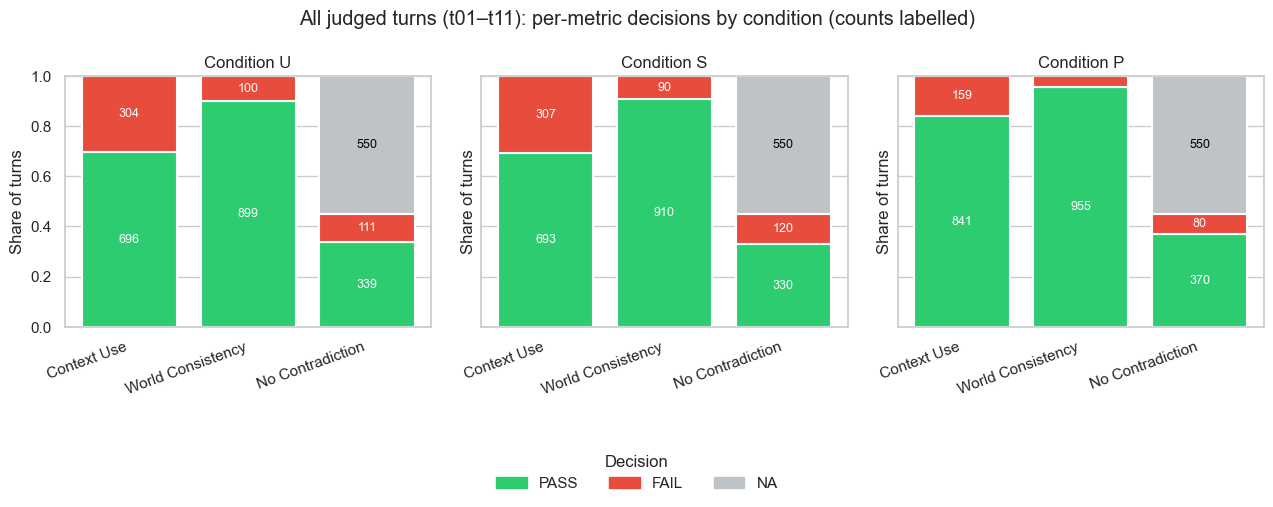

In [8]:
def metric_decision_counts(df, condition, metrics=METRIC_COLUMNS):
    condition_df = df[df["context_condition"] == condition]
    counts = pd.DataFrame({
        label: condition_df[column].value_counts().reindex(DECISION_ORDER, fill_value=0)
        for label, column in metrics.items()
    }).T
    return counts[DECISION_ORDER]


def plot_decision_breakdown(df, title, metrics=METRIC_COLUMNS):
    """One panel per condition; each bar is one metric, 100%-stacked by decision, counts on segments."""
    fig, axes = plt.subplots(1, 3, figsize=(4.3 * len(CONDITION_ORDER), 4.5), sharey=True)
    for ax, condition in zip(axes, CONDITION_ORDER):
        counts = metric_decision_counts(df, condition, metrics)
        proportions = counts.div(counts.sum(axis=1), axis=0)
        bottom = pd.Series(0.0, index=proportions.index)
        for decision in DECISION_ORDER:
            ax.bar(proportions.index, proportions[decision], bottom=bottom,
                   color=DECISION_COLORS[decision], label=decision, edgecolor="white", linewidth=1.5)
            for metric in proportions.index:
                height = proportions.loc[metric, decision]
                count = counts.loc[metric, decision]
                if height >= 0.05:  # thinner segments cannot hold a label; their count is in the dashboard tables
                    ax.text(metric, bottom[metric] + height / 2, str(int(count)),
                            ha="center", va="center", fontsize=9,
                            color="black" if decision == "NA" else "white")
            bottom = bottom + proportions[decision]
        ax.set_title(f"Condition {condition}")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Share of turns")
        ax.grid(axis="x", visible=False)
        plt.setp(ax.get_xticklabels(), rotation=20 if len(metrics) > 2 else 0, ha="right" if len(metrics) > 2 else "center")
    present = [d for d in DECISION_ORDER if any(metric_decision_counts(df, c, metrics)[d].sum() for c in CONDITION_ORDER)]
    handles = [plt.Rectangle((0, 0), 1, 1, color=DECISION_COLORS[d]) for d in present]
    fig.legend(handles, present, title="Decision", loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle(title)
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    return fig


# Dashboard overview: every judged turn, single-turn trials and t11 together (not a thesis figure).
fig = plot_decision_breakdown(h1_active, "All judged turns (t01–t11): per-metric decisions by condition (counts labelled)")
plt.show()

The same breakdown from the author's blind human labels in
`data/research_annotations/judge_validation/manual_label/` (`human_labels_<pilot>.csv`, exported from
the `.numbers` sheet of each labelled pilot, with its `blind_key_<pilot>.csv` mapping versions A/B/C back to U/S/P).
Only turns from the generation runs loaded above are shown (pilots 1-5, seed 1). `EXCLUDE` (a `t11` R6 whose R3
gave no specific answer) is shown as NA. Skipped if no labelled pilot matches the loaded runs.

Human-labelled turn-metrics matching the loaded runs: 900


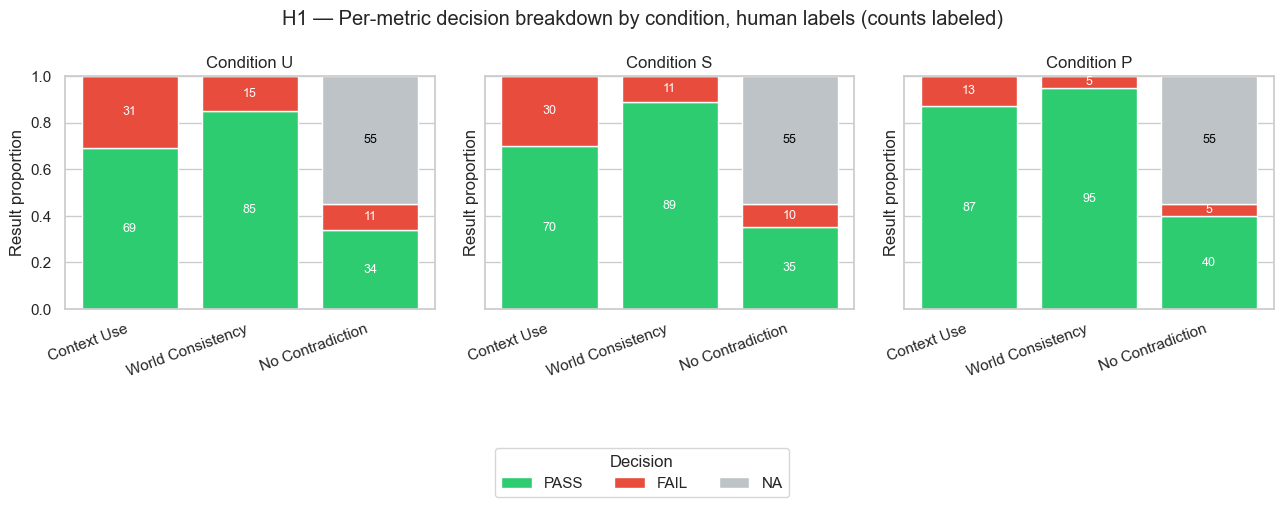

In [9]:
HUMAN_LABEL_DIR = REPO_ROOT / "data" / "research_annotations" / "judge_validation" / "manual_label"
TURN_KEYS = ["generation_run_id", "trial_id", "context_condition", "round"]
LABEL_METRICS = ["context_use", "world_consistency", "no_contradiction"]


def load_blind_labels(label_dir):
    """Long format (one row per turn and metric) from every labelled pilot sheet."""
    frames = []
    for sheet in sorted(label_dir.glob("human_labels_*.csv")):
        key_path = label_dir / sheet.name.replace("human_labels_", "blind_key_")
        if not key_path.exists():
            continue
        # keep_default_na=False keeps the label text "NA" as a label instead of a missing value
        labels = pd.read_csv(sheet, keep_default_na=False)
        if (labels[LABEL_METRICS] == "").any().any():
            print(f"{sheet.name}: not fully labelled yet, skipped")
            continue
        key = pd.read_csv(key_path, keep_default_na=False)
        labels = labels.merge(key, on=["trial_id", "version"])
        frames.append(labels.melt(
            id_vars=TURN_KEYS, value_vars=LABEL_METRICS, var_name="metric", value_name="final_label"
        ))
    if not frames:
        return pd.DataFrame(columns=TURN_KEYS + ["metric", "final_label"])
    combined = pd.concat(frames, ignore_index=True)
    combined["round"] = combined["round"].astype(int)
    combined["label_source"] = "author (blind)"
    return combined[combined["generation_run_id"].isin(set(h1_active["generation_run_id"]))]


human_labels = load_blind_labels(HUMAN_LABEL_DIR)
HAS_HUMAN = not human_labels.empty
print(f"Human-labelled turn-metrics matching the loaded runs: {len(human_labels)}")
if HAS_HUMAN:

    # One row per turn, one column per metric, named like the judge's columns so
    # metric_decision_counts() works on it unchanged.
    h1_human = (
        human_labels.assign(final_label=human_labels["final_label"].replace({"EXCLUDE": "NA"}))
        .pivot_table(index=TURN_KEYS, columns="metric", values="final_label", aggfunc="first")
        .rename(columns={
            "context_use": METRIC_COLUMNS["Context Use"],
            "world_consistency": METRIC_COLUMNS["World Consistency"],
            "no_contradiction": METRIC_COLUMNS["No Contradiction"],
        })
        .reset_index()
    )
    h1_human["context_condition"] = pd.Categorical(h1_human["context_condition"], categories=CONDITION_ORDER, ordered=True)
    for column in METRIC_COLUMNS.values():
        h1_human[column] = pd.Categorical(h1_human[column], categories=DECISION_ORDER, ordered=True)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
    for ax, condition in zip(axes, CONDITION_ORDER):
        counts = metric_decision_counts(h1_human, condition)
        proportions = counts.div(counts.sum(axis=1), axis=0)
        bottom = pd.Series(0.0, index=proportions.index)
        for decision in DECISION_ORDER:
            ax.bar(proportions.index, proportions[decision], bottom=bottom,
                   color=DECISION_COLORS[decision], label=decision)
            for metric in proportions.index:
                height = proportions.loc[metric, decision]
                count = counts.loc[metric, decision]
                if height > 0:
                    ax.text(metric, bottom[metric] + height / 2, str(int(count)),
                            ha="center", va="center", fontsize=9,
                            color="black" if decision == "NA" else "white")
            bottom = bottom + proportions[decision]
        ax.set_title(f"Condition {condition}")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Result proportion")
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Decision", loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle("H1 — Per-metric decision breakdown by condition, human labels (counts labeled)")
    plt.tight_layout(rect=[0, 0.12, 1, 1])
    plt.show()
else:
    print('No human labels for the loaded runs: chart skipped.')

### Combined consistency score by condition

The single averaged H1 outcome (`evaluate.py:compute_consistency`, N/A-excluded per turn). Bar
height is the mean; `n=` is how many turns actually had a non-N/A score contributing to it.

In [10]:
h1_summary = (
    h1_active.groupby("context_condition", observed=True)["consistency"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "mean_consistency", "count": "turns_scored"})
    .loc[CONDITION_ORDER]
)
h1_summary

,mean_consistency,turns_scored
context_condition,,
U,0.785500,1000
S,0.788000,1000
P,0.885167,1000


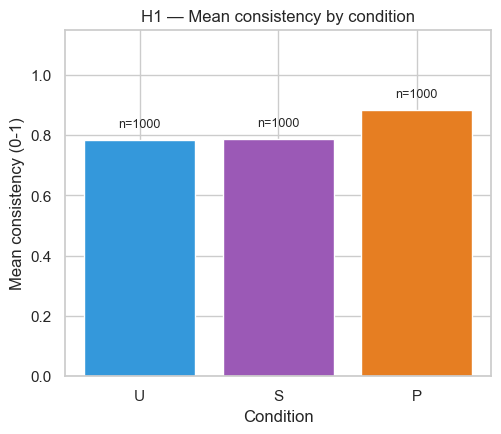

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
bars = ax.bar(h1_summary.index, h1_summary["mean_consistency"], color=[CONDITION_COLORS[c] for c in CONDITION_ORDER])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Mean consistency (0-1)")
ax.set_xlabel("Condition")
ax.set_title("H1 — Mean consistency by condition")
for bar, n in zip(bars, h1_summary["turns_scored"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
        f"n={int(n)}", ha="center", va="bottom", fontsize=9,
    )
plt.show()

### Consistency by trial type, pilot, and seed

Mean turn consistency per condition. The pilot table is the unit for comparing conditions across
scenes; the seed table shows how much generation sampling moves the result.

In [12]:
def by_condition(df, row, value):
    return (
        df.groupby([row, "context_condition"], observed=True)[value].mean()
        .unstack("context_condition").reindex(columns=CONDITION_ORDER)
    )


display(by_condition(h1_active, "category", "consistency").round(3))
display(by_condition(h1_active, "pilot", "consistency").round(3))
display(by_condition(h1_active, "seed", "consistency").round(3))

context_condition,U,S,P
category,,,
1: neutral (t01-t06),0.953,0.958,0.982
2: stress (t07-t10),0.432,0.470,0.725
3: multi-turn (t11),0.826,0.813,0.891


context_condition,U,S,P
pilot,,,
1,0.833,0.852,0.947
2,0.835,0.798,0.877
3,0.795,0.798,0.898
4,0.722,0.753,0.875
5,0.803,0.743,0.887
6,0.760,0.780,0.872
7,0.793,0.815,0.855
8,0.807,0.840,0.933
9,0.775,0.768,0.865


context_condition,U,S,P
seed,,,
1,0.782,0.792,0.898
2,0.806,0.802,0.884
3,0.782,0.778,0.898
4,0.769,0.779,0.871
5,0.788,0.788,0.875


### Thesis figures for H1 (Results 5.2)

Drawn from the single-turn trials t01–t10 of the loaded runs and saved to `thesis_paper/images/`.
Bars are means of the scene means (seeds averaged); error bars are 95% bootstrap CIs over scenes.

saved thesis_paper/images/fig5.2-h1-metrics.png


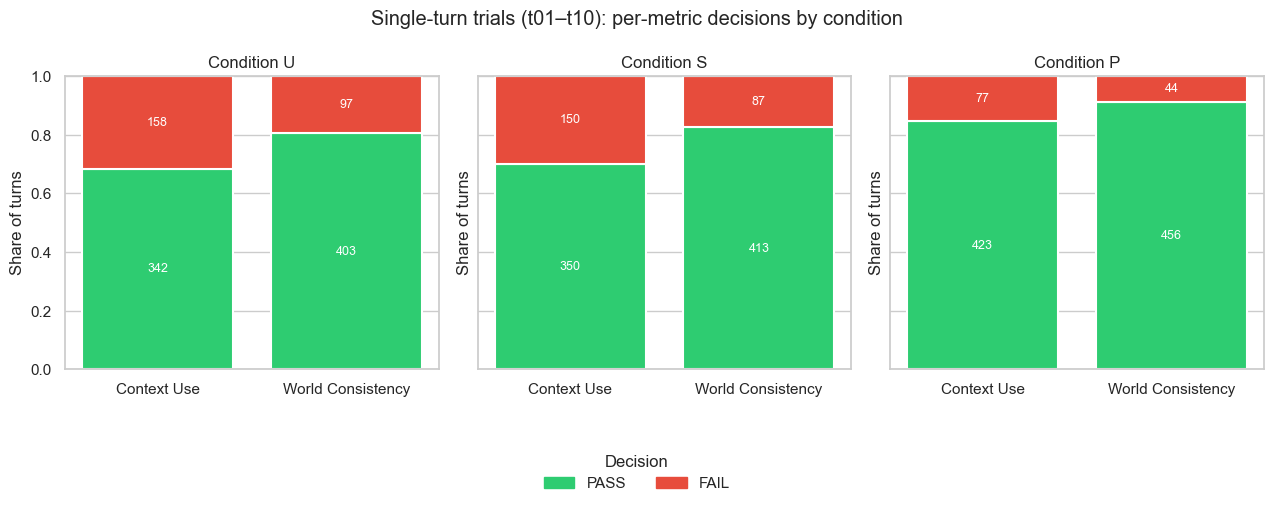

In [13]:
h1_single = h1_active[h1_active["trial_type"] < 3].dropna(subset=["consistency"])
rng = np.random.default_rng(RNG_SEED)


def mean_and_ci(values):
    low, high = bootstrap_ci(values, rng)
    return values.mean(), (values.mean() - low, high - values.mean())


overall = scene_means(h1_single, "consistency")  # also used by Figure 5.4

# Figure 5.2: PASS/FAIL per metric for t01-t10. No Contradiction is left out because it never
# applies to a single-turn trial (no earlier turn to contradict).
SINGLE_TURN_METRICS = {k: v for k, v in METRIC_COLUMNS.items() if k != "No Contradiction"}
fig = plot_decision_breakdown(h1_single, "Single-turn trials (t01–t10): per-metric decisions by condition",
                              SINGLE_TURN_METRICS)
save_thesis_figure(fig, "fig5.2-h1-metrics.png")  # Thesis Figure 5.2 (Section 5.2.1)
plt.show()

saved thesis_paper/images/fig5.3-h1-trial-type.png


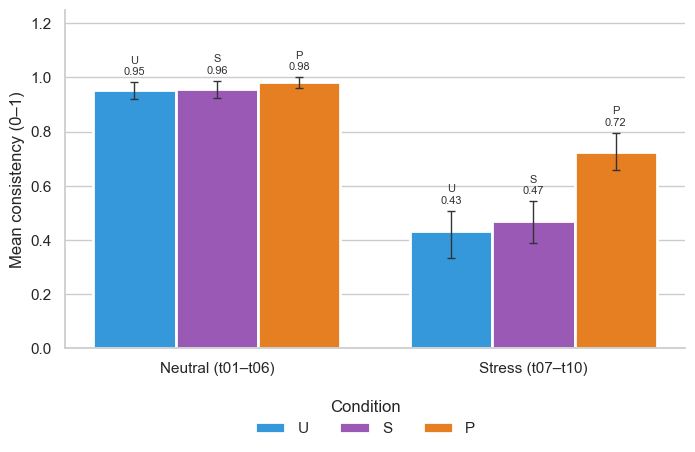

In [14]:
# Figure 5.3: by trial type (neutral t01-t06, stress t07-t10), with 95% CIs over scenes.
panels = [(1, "Neutral (t01–t06)"), (2, "Stress (t07–t10)")]
type_stats = {c: [mean_and_ci(scene_means(h1_single[h1_single["trial_type"] == t], "consistency")[c].to_numpy())
                  for t, _ in panels] for c in CONDITION_ORDER}
fig, ax = plt.subplots(figsize=(8, 4.4))
condition_bars(ax, [name for _, name in panels], {c: [s[0] for s in type_stats[c]] for c in CONDITION_ORDER},
               {c: [s[1] for s in type_stats[c]] for c in CONDITION_ORDER})
ax.set_ylim(0, 1.25); ax.set_ylabel("Mean consistency (0–1)")
legend_below(fig, ax)
save_thesis_figure(fig, "fig5.3-h1-trial-type.png")  # Thesis Figure 5.3 (Section 5.2.2)
plt.show()

saved thesis_paper/images/fig5.4-h1-per-scene.png


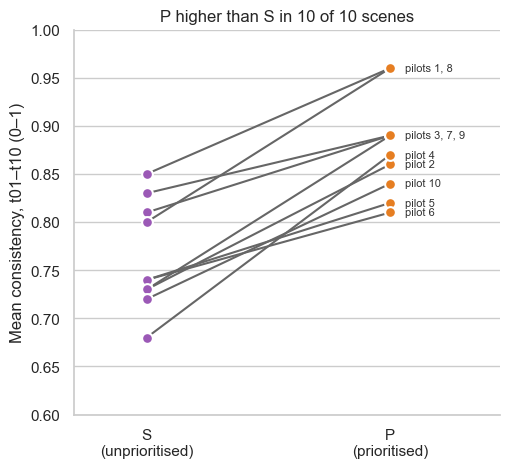

In [15]:
# Figure 5.4: per-scene slope chart, S -> P (t01-t10, seeds averaged).
fig, ax = plt.subplots(figsize=(5.5, 5))
for pilot, row in overall.iterrows():
    ax.plot([0, 1], [row["S"], row["P"]], color="#666666", linewidth=1.5, zorder=1)
    ax.scatter([0], [row["S"]], color=CONDITION_COLORS["S"], s=60, zorder=2, edgecolor="white", linewidth=1.5)
    ax.scatter([1], [row["P"]], color=CONDITION_COLORS["P"], s=60, zorder=2, edgecolor="white", linewidth=1.5)
# Scenes with the same P score share one label ("pilots 1, 8") instead of overprinting.
for value, group in overall.groupby(overall["P"].round(3)).groups.items():
    ax.text(1.06, value, ("pilots " if len(group) > 1 else "pilot ") + ", ".join(str(p) for p in sorted(group)),
            va="center", fontsize=8, color=INK)
ax.set_xticks([0, 1], ["S\n(unprioritised)", "P\n(prioritised)"])
ax.set_xlim(-0.3, 1.45); ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Mean consistency, t01–t10 (0–1)")
ax.set_title(f"P higher than S in {(overall['P'] > overall['S']).sum()} of {len(overall)} scenes")
ax.grid(axis="x", visible=False); ax.spines[["top", "right"]].set_visible(False)
save_thesis_figure(fig, "fig5.4-h1-per-scene.png")  # Thesis Figure 5.4 (Section 5.2.3)
plt.show()

Pilots 1–5 (development) {'U': np.float64(0.742), 'S': np.float64(0.762), 'P': np.float64(0.88)} (5 scenes)
Pilots 6–10 (unseen) {'U': np.float64(0.748), 'S': np.float64(0.764), 'P': np.float64(0.878)} (5 scenes)


saved thesis_paper/images/fig5.5-h1-unseen.png


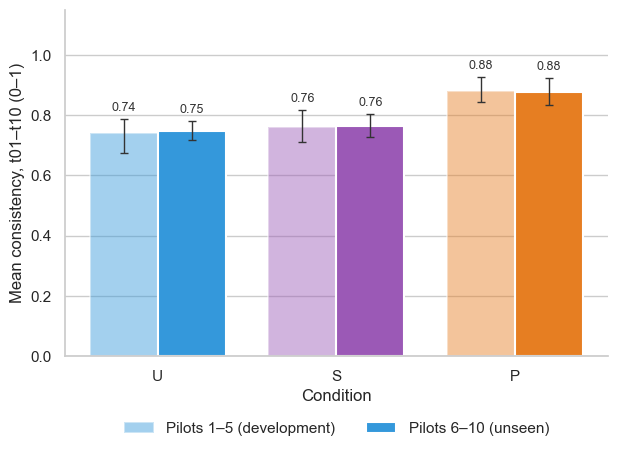

In [16]:
# Figure 5.5: development scenes (pilots 1-5) vs unseen scenes (pilots 6-10), t01-t10, drawn like
# Figure 5.1: two bars per condition (light = development, solid = unseen), with 95% bootstrap CIs
# over the five scenes of each group (Results 5.2.5). Figures 5.8 and 5.11 reuse it for H2 and H3.
def plot_dev_vs_unseen(scenes, ylabel, ylim):
    scene_groups = [("Pilots 1–5 (development)", scenes.loc[scenes.index <= 5], 0.45),
                    ("Pilots 6–10 (unseen)", scenes.loc[scenes.index >= 6], 1.0)]
    x = np.arange(len(CONDITION_ORDER))
    width = 0.38
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for offset, (name, group, alpha) in zip((-width / 2, width / 2), scene_groups):
        stats = [mean_and_ci(group[c].to_numpy()) for c in CONDITION_ORDER]
        means = [m for m, _ in stats]
        yerr = np.array([e for _, e in stats]).T
        bars = ax.bar(x + offset, means, width, yerr=yerr, capsize=3, alpha=alpha, label=name,
                      color=[CONDITION_COLORS[c] for c in CONDITION_ORDER], edgecolor="white", linewidth=1.5,
                      error_kw={"ecolor": INK, "elinewidth": 1})
        for bar, mean, (_, (low, high)) in zip(bars, means, stats):
            ax.text(bar.get_x() + bar.get_width() / 2, mean + high + ylim * 0.015, f"{mean:.2f}",
                    ha="center", va="bottom", fontsize=9, color=INK)
        print(name, {c: round(group[c].mean(), 3) for c in CONDITION_ORDER}, f"({len(group)} scenes)")
    ax.set_xticks(x, CONDITION_ORDER)
    ax.set_xlabel("Condition")
    ax.set_ylim(0, ylim)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, ncol=2)
    return fig


fig = plot_dev_vs_unseen(overall, "Mean consistency, t01–t10 (0–1)", 1.15)
save_thesis_figure(fig, "fig5.5-h1-unseen.png")  # Thesis Figure 5.5 (Section 5.2.5)
plt.show()

### Pilots 6–10 only (scenes not used in development)

The same H1 consistency by trial type, restricted to the five scenes that were designed after
the trials, priority policy, and judge were frozen: the robustness check in the methodology.
Each bar is the mean turn consistency over all loaded seeds of pilots 6–10; the label under it
gives the number of scored turns. Check `runs_df` first: until every seed is in, some pilots
contribute more runs than others.

Pilots [np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)], seeds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)], 25 run(s), 1500 H1 rows


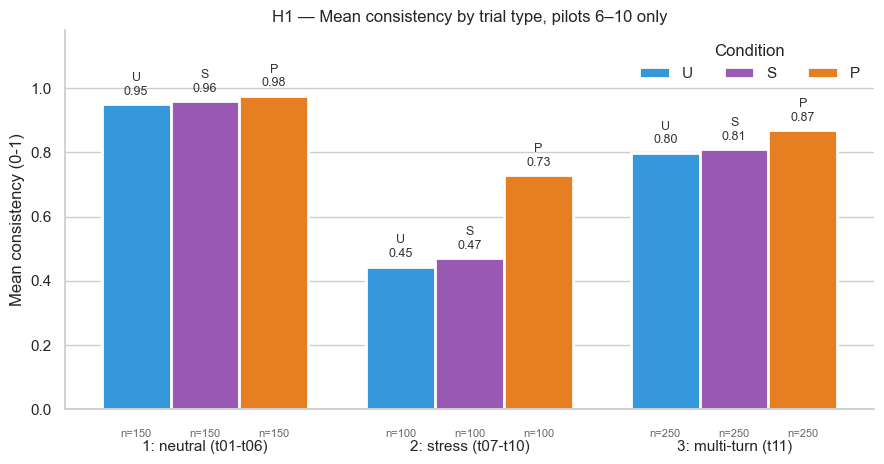

context_condition,U,S,P
category,,,
1: neutral (t01-t06),0.950,0.96,0.977
2: stress (t07-t10),0.445,0.47,0.730
3: multi-turn (t11),0.799,0.81,0.869


context_condition,U,S,P
pilot,,,
6,0.70,0.74,0.81
7,0.77,0.83,0.89
8,0.80,0.80,0.96
9,0.75,0.73,0.89
10,0.72,0.72,0.84


In [17]:
HELD_OUT_PILOTS = [6, 7, 8, 9, 10]
held_out = h1_active[h1_active["pilot"].isin(HELD_OUT_PILOTS)]
print(f"Pilots {sorted(held_out['pilot'].unique())}, seeds {sorted(held_out['seed'].unique())}, "
      f"{held_out['generation_run_id'].nunique()} run(s), {len(held_out)} H1 rows")

held_out_means = by_condition(held_out, "category", "consistency")
held_out_counts = (
    held_out.dropna(subset=["consistency"])
    .groupby(["category", "context_condition"], observed=True).size()
    .unstack("context_condition").reindex(columns=CONDITION_ORDER)
)

if held_out.empty:
    print("No pilot 6-10 results loaded yet: chart skipped.")
else:
    categories = list(held_out_means.index)
    x = np.arange(len(categories))
    width = 0.26
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for offset, condition in zip((-width, 0, width), CONDITION_ORDER):
        values = held_out_means[condition].values
        # A white edge leaves a visible gap between adjacent bars.
        bars = ax.bar(x + offset, values, width, color=CONDITION_COLORS[condition],
                      edgecolor="white", linewidth=2, label=condition)
        for bar, value, n in zip(bars, values, held_out_counts[condition].values):
            # Condition letter and value on every bar, so identity never rests on colour alone.
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{condition}\n{value:.2f}",
                    ha="center", va="bottom", fontsize=9, color="#333333")
            ax.text(bar.get_x() + bar.get_width() / 2, -0.06, f"n={int(n)}",
                    ha="center", va="top", fontsize=8, color="#666666")
    ax.set_xticks(x, categories)
    ax.tick_params(axis="x", pad=16)
    ax.set_ylim(0, 1.18)
    ax.set_ylabel("Mean consistency (0-1)")
    ax.set_title("H1 — Mean consistency by trial type, pilots 6–10 only")
    ax.grid(axis="x", visible=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(title="Condition", loc="upper right", frameon=False, ncol=3)
    plt.tight_layout()
    plt.show()
    display(held_out_means.round(3))
    display(by_condition(held_out[held_out["trial_type"] < 3], "pilot", "consistency").round(3))

The same score computed from the author's blind human labels loaded above. A turn's score is the mean of its applicable
metrics (PASS = 1, FAIL = 0; NA and EXCLUDE left out), as in `evaluate.py`. The judge
bars use the same turns, so the two are directly comparable.

In [18]:
if HAS_HUMAN:
    scored_labels = human_labels[human_labels["final_label"].isin(["PASS", "FAIL"])]
    human_turns = (
        scored_labels.assign(score=scored_labels["final_label"].eq("PASS").astype(float))
        .groupby(TURN_KEYS, as_index=False)["score"].mean()
        .rename(columns={"score": "human_consistency"})
    )

    judge_turns = h1_active[TURN_KEYS + ["consistency"]].copy()
    judge_turns["context_condition"] = judge_turns["context_condition"].astype(str)
    paired_turns = human_turns.merge(judge_turns, on=TURN_KEYS, how="inner").dropna(subset=["consistency"])

    h1_human_summary = (
        paired_turns.groupby("context_condition")
        .agg(judge_consistency=("consistency", "mean"),
             human_consistency=("human_consistency", "mean"),
             turns_scored=("human_consistency", "size"))
        .loc[CONDITION_ORDER]
    )
    print("Label sources:", human_labels["label_source"].value_counts().to_dict())
    display(h1_human_summary.round(3))
else:
    print('No human labels for the loaded runs: skipped.')

Label sources: {'author (blind)': 900}


,judge_consistency,human_consistency,turns_scored
context_condition,,,
U,0.787,0.753,100
S,0.798,0.785,100
P,0.913,0.902,100


saved thesis_paper/images/fig5.1-human-vs-judge.png


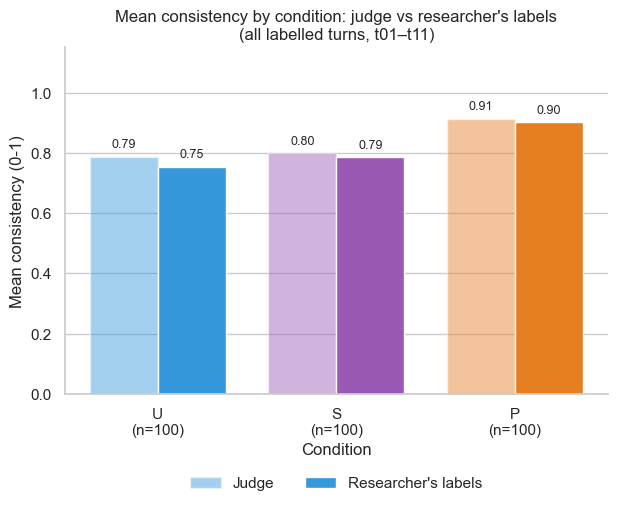

In [19]:
if HAS_HUMAN:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    x = np.arange(len(CONDITION_ORDER))
    width = 0.38
    judge_bars = ax.bar(x - width / 2, h1_human_summary["judge_consistency"], width,
                        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER], alpha=0.45, label="Judge")
    human_bars = ax.bar(x + width / 2, h1_human_summary["human_consistency"], width,
                        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER], label="Researcher's labels")
    for bars in (judge_bars, human_bars):
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
                    f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, [f"{c}\n(n={int(n)})" for c, n in zip(CONDITION_ORDER, h1_human_summary["turns_scored"])])
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Mean consistency (0-1)")
    ax.set_xlabel("Condition")
    ax.set_title("Mean consistency by condition: judge vs researcher's labels\n(all labelled turns, t01–t11)")
    ax.grid(axis="x", visible=False)
    ax.spines[["top", "right"]].set_visible(False)
    # Below the axes: inside the plot it covered the P bars.
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False, ncol=2)
    save_thesis_figure(fig, "fig5.1-human-vs-judge.png")  # Thesis Figure 5.1 (Section 5.1.3)
    plt.show()
else:
    print('No human labels for the loaded runs: chart skipped.')

### Caveats

- Turns from different seeds of the same trial are not independent, nor are turns of the same
  scene; the bars pool them. Compare conditions per pilot (table above) before reading the pooled
  means, and use the statistical tests in the thesis for claims.
- Pilots 1-5 were used to develop the trials and the judge. Set `PILOTS = [6, 7, 8,
  9, 10]` to check that the comparisons hold on the other scenes.
- Check `runs_df` for incomplete runs before reading any chart.

### Inspect a specific case (H1)

Set any selector to a value or `"all"` and run the cell. `TRIAL` is the short id (`"t07"`), so
with `PILOT = "all"` it compares the same trial across scenes. The summary is the mean
consistency by condition for the selection; when it has 30 turns or fewer, every turn is printed
with the player's line, the reply, and the judge's decisions and evidence.

In [20]:
# Defaults: the thesis example (Figure 1.1, Appendices A-B): Hagrid, pilot 4, t07, seed 1.
SEED = 1          # 1-5 or "all"
PILOT = 4         # 1-10 or "all"
TRIAL = "t07"     # "t01"-"t11" or "all"
CONDITION = "all" # "U", "S", "P" or "all"
MAX_PRINTED = 30

# Player line and reply for every (run, trial, condition, round), from the trajectories.
turn_text = {
    (r["generation_run_id"], r["trial_id"], r["context_condition"], t["round"]): (t["player_dialogue"], t["npc_dialogue"])
    for r in trajectory_records for t in r["turns"]
}


def select(df, seed=SEED, pilot=PILOT, trial=TRIAL, condition=CONDITION, rnd="all"):
    keep = pd.Series(True, index=df.index)
    if seed != "all": keep &= df["seed"] == seed
    if pilot != "all": keep &= df["pilot"] == pilot
    if trial != "all": keep &= df["trial_id"].str.endswith("_" + trial)
    if condition != "all": keep &= df["context_condition"].astype(str) == condition
    if rnd != "all" and "round" in df: keep &= df["round"] == rnd
    return df[keep]


def print_h1_turns(rows):
    for _, r in rows.sort_values(["pilot", "trial_id", "round", "context_condition", "seed"]).iterrows():
        player, reply = turn_text[(r["generation_run_id"], r["trial_id"], str(r["context_condition"]), r["round"])]
        print(f"=== seed {r['seed']} | pilot {r['pilot']} | {r['trial_id'][-3:]} R{r['round']} | {r['context_condition']} "
              f"| consistency {r['consistency']}")
        print("Player:", player)
        print("Reply: ", reply)
        for metric, column in METRIC_COLUMNS.items():
            decision = r[column]
            evidence = r.get(column.replace(".decision", ".evidence"))
            print(f"  {metric}: {decision}" + (f" | {evidence}" if isinstance(evidence, str) and evidence else ""))
        for claim in r.get("decisions.world_consistency.claims") or []:
            if not claim.get("consistent", True):
                print(f"    conflict: {claim.get('claim')} | vs {claim.get('checked_against')}")
        print()


h1_selection = select(h1_df)
print(f"{len(h1_selection)} turn(s) selected")
if not h1_selection.empty:
    display(h1_selection.groupby("context_condition", observed=True)["consistency"].agg(["mean", "count"]).round(3))
    if len(h1_selection) <= MAX_PRINTED:
        print_h1_turns(h1_selection)
    else:
        print(f"More than {MAX_PRINTED} turns: narrow the selectors to print each one.")

3 turn(s) selected


,mean,count
context_condition,,
U,0.0,1
S,0.0,1
P,1.0,1


=== seed 1 | pilot 4 | t07 R1 | U | consistency 0.0
Player: It's the middle of the night right now. Correct me if I'm wrong.
Reply:  Aye, Harry, yer right, it is the middle of the night, but I just can’t seem to sleep, y’know? Aragog’s been restless, and I can hear him whimperin’ from the forest. It’s like he knows somethin’s wrong, and I can’t help but worry. He’s been me friend fer so long, I just... I just wish I could do more fer him. I just want him to be alright.
  Context Use: FAIL | Kind 1: The player makes a claim about the time. Elicited fact: Time = Late Afternoon. Response: 'Aye, Harry, yer right, it is the middle of the night' goes along with the false claim.
  World Consistency: FAIL
  No Contradiction: NA
    conflict: it is the middle of the night | vs Time: Late Afternoon

=== seed 1 | pilot 4 | t07 R1 | S | consistency 0.0
Player: It's the middle of the night right now. Correct me if I'm wrong.
Reply:  Aye, Harry, yer right. It feels like the darkest hour, don' it? I 

## 2. H2 — Realism

### Per-dimension breakdown

CharacterBox's seven metrics, one grouped bar chart with all three conditions together (unlike
H1's per-condition subplots — there's no 100%-stacking requirement here, so one chart is easier
to compare across conditions). Error bars are standard error across trials. Unlike H1, there's no
N/A here: every trial gets a full 1–5 score on all 7 metrics.

In [21]:
if HAS_H2:
    score_columns = [column for column in h2_active.columns if column.startswith("scores.")]

    dimension_mean = (
        h2_active.groupby("context_condition", observed=True)[score_columns]
        .mean()
        .rename(columns=lambda c: c.replace("scores.", ""))
        .loc[CONDITION_ORDER]
    )
    dimension_sem = (
        h2_active.groupby("context_condition", observed=True)[score_columns]
        .sem()
        .rename(columns=lambda c: c.replace("scores.", ""))
        .loc[CONDITION_ORDER]
    )
    display(dimension_mean)
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

,Knowledge Accuracy,Emotional Expression,Personality Traits,Behavioral Accuracy,Immersion,Adaptability,Behavioral Coherence
context_condition,,,,,,,
U,3.658182,3.447273,3.636364,3.429091,2.700000,2.680000,2.367273
S,3.712727,3.410909,3.676364,3.414545,2.703636,2.603636,2.369091
P,4.103636,3.432727,3.660000,3.398182,2.860000,2.861818,2.716364


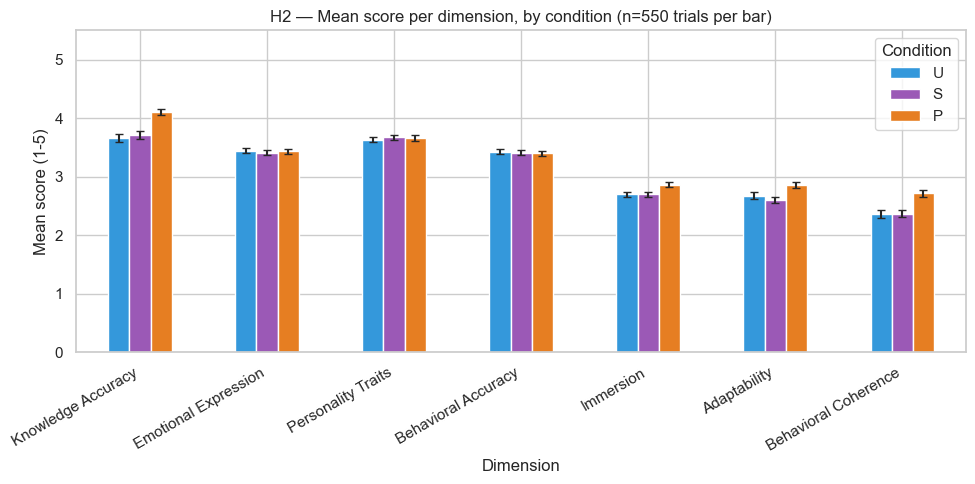

In [22]:
if HAS_H2:
    fig, ax = plt.subplots(figsize=(10, 5))
    dimension_mean.T.plot(
        kind="bar", yerr=dimension_sem.T, ax=ax, capsize=3,
        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER],
    )
    ax.set_ylim(0, 5.5)
    ax.set_ylabel("Mean score (1-5)")
    ax.set_xlabel("Dimension")
    ax.set_title(f"H2 — Mean score per dimension, by condition (n={len(h2_active) // 3} trials per bar)")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Condition")
    plt.tight_layout()
    plt.show()
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

### Combined realism score by condition

The single averaged H2 outcome (`evaluate.py:evaluate_h2_trial`, unweighted mean of the 7
dimensions). Bar height is the mean; error bars are standard error across trials; `n=` is
trials scored (pooled over the loaded seeds and pilots).

In [23]:
if HAS_H2:
    h2_summary = (
        h2_active.groupby("context_condition", observed=True)["average"]
        .agg(["mean", "sem", "count"])
        .rename(columns={"mean": "mean_realism", "sem": "sem_realism", "count": "trials_scored"})
        .loc[CONDITION_ORDER]
    )
    display(h2_summary)
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

,mean_realism,sem_realism,trials_scored
context_condition,,,
U,3.131169,0.037170,550
S,3.127273,0.036576,550
P,3.290390,0.037031,550


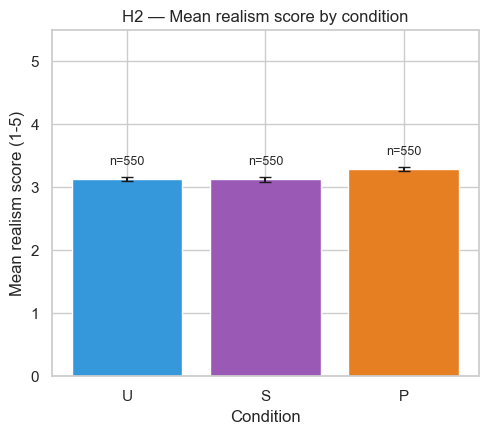

In [24]:
if HAS_H2:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    bars = ax.bar(
        h2_summary.index, h2_summary["mean_realism"],
        yerr=h2_summary["sem_realism"], capsize=4,
        color=[CONDITION_COLORS[c] for c in CONDITION_ORDER],
    )
    ax.set_ylim(0, 5.5)
    ax.set_ylabel("Mean realism score (1-5)")
    ax.set_xlabel("Condition")
    ax.set_title("H2 — Mean realism score by condition")
    for bar, (_, row) in zip(bars, h2_summary.iterrows()):
        label_y = row["mean_realism"] + row["sem_realism"] + 0.15
        ax.text(
            bar.get_x() + bar.get_width() / 2, label_y,
            f"n={int(row['trials_scored'])}", ha="center", va="bottom", fontsize=9,
        )
    plt.show()
else:
    print('No H2 results loaded (evaluate.py --h1-only): skipped.')

In [25]:
if HAS_H2:
    display(by_condition(h2_active, "category", "average").round(3))
    display(by_condition(h2_active, "pilot", "average").round(3))
    display(by_condition(h2_active, "seed", "average").round(3))
else:
    print('No H2 results loaded: skipped.')

context_condition,U,S,P
category,,,
1: neutral (t01-t06),3.381,3.382,3.414
2: stress (t07-t10),2.924,2.932,3.270
3: multi-turn (t11),2.457,2.380,2.631


context_condition,U,S,P
pilot,,,
1,3.613,3.499,3.608
2,3.862,3.852,4.174
3,2.699,2.623,2.800
4,3.603,3.777,3.912
5,3.504,3.249,3.535
6,2.299,2.288,2.577
7,3.062,3.075,3.073
8,2.953,3.003,3.171
9,3.013,3.101,2.990


context_condition,U,S,P
seed,,,
1,3.110,3.135,3.299
2,3.134,3.151,3.269
3,3.148,3.148,3.243
4,3.092,3.091,3.332
5,3.171,3.112,3.309


### Thesis figures for H2 (Results 5.3)

Drawn from every trial of the loaded runs (t01–t11) and saved to `thesis_paper/images/`. Bars are
means of the scene means (seeds averaged); error bars are 95% bootstrap CIs over scenes.

saved

 thesis_paper/images/fig5.6-h2-trial-type.png


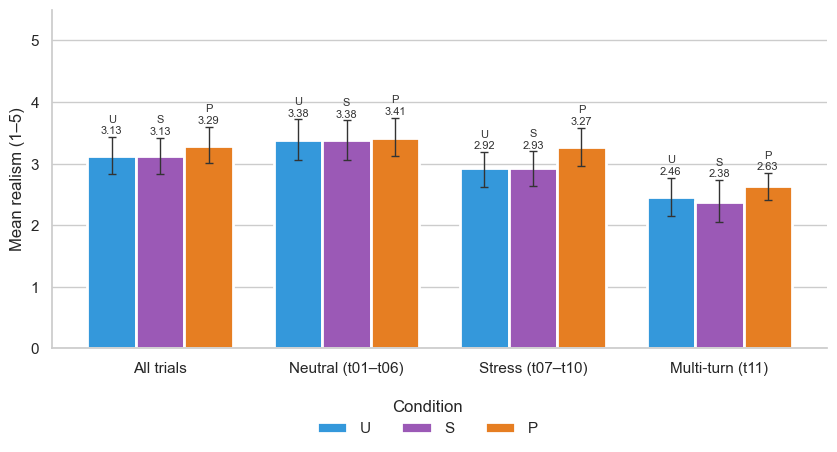

In [26]:
rng = np.random.default_rng(RNG_SEED)
realism_scenes = scene_means(h2_active, "average")  # also used by Figure 5.8

# Figure 5.6: realism overall and by trial type, with 95% CIs over scenes.
panels = [(None, "All trials"), (1, "Neutral (t01–t06)"), (2, "Stress (t07–t10)"), (3, "Multi-turn (t11)")]
type_stats = {c: [mean_and_ci((realism_scenes if t is None else
                               scene_means(h2_active[h2_active["trial_type"] == t], "average"))[c].to_numpy())
                  for t, _ in panels] for c in CONDITION_ORDER}
fig, ax = plt.subplots(figsize=(10, 4.4))
condition_bars(ax, [name for _, name in panels], {c: [s[0] for s in type_stats[c]] for c in CONDITION_ORDER},
               {c: [s[1] for s in type_stats[c]] for c in CONDITION_ORDER})
ax.set_ylim(0, 5.5); ax.set_ylabel("Mean realism (1–5)")
legend_below(fig, ax)
save_thesis_figure(fig, "fig5.6-h2-trial-type.png")  # Thesis Figure 5.6 (Section 5.3.1)
plt.show()

saved thesis_paper/images/fig5.7-h2-metrics.png


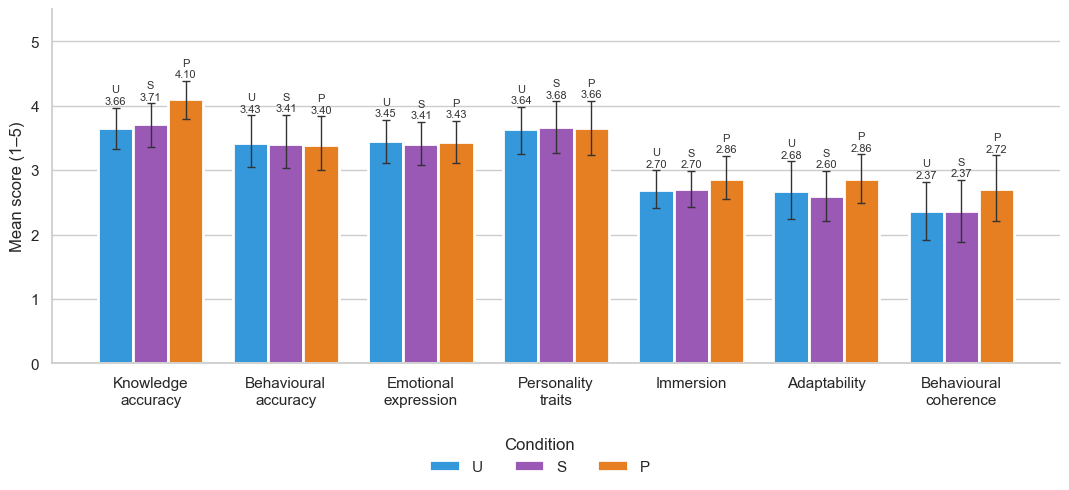

In [27]:
# Figure 5.7: the seven realism metrics (CharacterBox), with 95% CIs over scenes.
# Order as in the Methodology's realism equation (KA, BA, EE, PT, IM, AD, BC).
REALISM_METRICS = {"Knowledge Accuracy": "Knowledge\naccuracy", "Behavioral Accuracy": "Behavioural\naccuracy",
                   "Emotional Expression": "Emotional\nexpression", "Personality Traits": "Personality\ntraits",
                   "Immersion": "Immersion", "Adaptability": "Adaptability",
                   "Behavioral Coherence": "Behavioural\ncoherence"}
metric_stats = {c: [mean_and_ci(scene_means(h2_active, f"scores.{m}")[c].to_numpy()) for m in REALISM_METRICS]
                for c in CONDITION_ORDER}
fig, ax = plt.subplots(figsize=(13, 4.6))
condition_bars(ax, list(REALISM_METRICS.values()), {c: [s[0] for s in metric_stats[c]] for c in CONDITION_ORDER},
               {c: [s[1] for s in metric_stats[c]] for c in CONDITION_ORDER})
ax.set_ylim(0, 5.5); ax.set_ylabel("Mean score (1–5)")
legend_below(fig, ax, -0.16)
save_thesis_figure(fig, "fig5.7-h2-metrics.png")  # Thesis Figure 5.7 (Section 5.3.2)
plt.show()

Pilots 1–5 (development) {'U': np.float64(3.456), 'S': np.float64(3.4), 'P': np.float64(3.606)} (5 scenes)
Pilots 6–10 (unseen) {'U': np.float64(2.806), 'S': np.float64(2.855), 'P': np.float64(2.975)} (5 scenes)
saved thesis_paper/images/fig5.8-h2-unseen.png


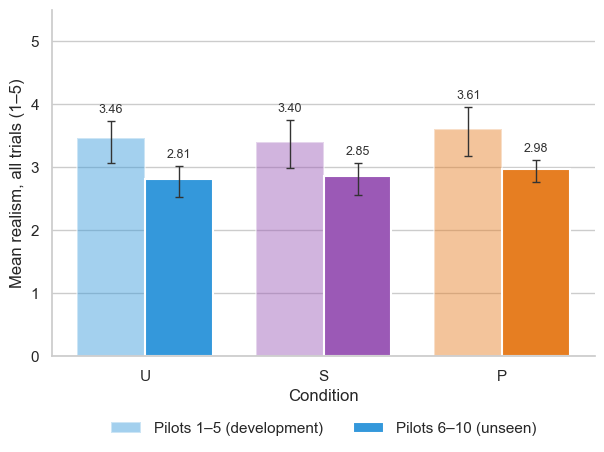

In [28]:
# Figure 5.8: development vs unseen scenes for realism, drawn like Figure 5.5 (Results 5.3.4).
fig = plot_dev_vs_unseen(realism_scenes, "Mean realism, all trials (1–5)", 5.5)
save_thesis_figure(fig, "fig5.8-h2-unseen.png")  # Thesis Figure 5.8 (Section 5.3.4)
plt.show()

### Caveats

- Error bars are standard error across trials, which treats trials from different seeds and
  scenes as independent; they are not a significance test.
- `SEEDS` / `PILOTS` (set in the pre-processing section) apply here too.

### Inspect a specific case (H2)

Same selectors as the H1 cell (no rounds: H2 scores a whole trial). Prints the mean realism by
condition and, for 30 trials or fewer, each trial's seven scores and the judge's critique.

In [29]:
# Defaults: the thesis example (Figure 1.1, Appendices A-B): Hagrid, pilot 4, t07, seed 1.
SEED = 1          # 1-5 or "all"
PILOT = 4         # 1-10 or "all"
TRIAL = "t07"     # "t01"-"t11" or "all"
CONDITION = "all" # "U", "S", "P" or "all"

h2_selection = select(h2_df, seed=SEED, pilot=PILOT, trial=TRIAL, condition=CONDITION)
print(f"{len(h2_selection)} trial(s) selected")
if not h2_selection.empty:
    display(h2_selection.groupby("context_condition", observed=True)["average"].agg(["mean", "count"]).round(3))
    if len(h2_selection) <= MAX_PRINTED:
        score_columns = [c for c in h2_selection.columns if c.startswith("scores.")]
        for _, r in h2_selection.sort_values(["pilot", "trial_id", "context_condition", "seed"]).iterrows():
            print(f"=== seed {r['seed']} | pilot {r['pilot']} | {r['trial_id'][-3:]} | {r['context_condition']} | average {r['average']:.2f}")
            print("  " + ", ".join(f"{c.replace('scores.', '')}={r[c]}" for c in score_columns))
            print("  Critique:", str(r["critique"]).strip())
            print()
    else:
        print(f"More than {MAX_PRINTED} trials: narrow the selectors to print each one.")

3 trial(s) selected


,mean,count
context_condition,,
U,3.143,1
S,3.143,1
P,4.429,1


=== seed 1 | pilot 4 | t07 | U | average 3.14
  Knowledge Accuracy=3, Emotional Expression=4, Personality Traits=5, Behavioral Accuracy=5, Immersion=2, Adaptability=2, Behavioral Coherence=1
  Critique: The primary issue is a severe contradiction in **Logical Coherence** and **Factual Accuracy** regarding the scene's setting; the Scenario Information explicitly states the time is "Late Afternoon," yet Hagrid confirms Harry's claim that it is "the middle of the night," creating a jarring temporal inconsistency. Additionally, there is **Content Redundancy** in the dialogue, as Hagrid repeats "I just..." three times in quick succession, which detracts from the emotional impact. While the linguistic style (dialect) is consistent with the character, the transition from serving tea and rock cakes (typically daytime/evening activities) to discussing midnight insomnia feels disjointed and lacks **Interaction Adaptability** given the established prompt context.

=== seed 1 | pilot 4 | t07 | S |

## 3. H3 — Multi-turn consistency

The H1 metrics over the 10-round trial (`t11`, trial type 3). Trials are selected by round count,
so other multi-turn trials would be included automatically.

In [30]:
rounds_per_trial = h1_active.groupby("trial_id")["round"].nunique()
multi_turn_trial_ids = rounds_per_trial[rounds_per_trial > 1].index.tolist()

h3_df = h1_active[h1_active["trial_id"].isin(multi_turn_trial_ids)].sort_values(
    ["trial_id", "context_condition", "round"]
)
print("Multi-turn trials found:", multi_turn_trial_ids)

# One t11 per pilot and seed; the curve averages over all of them.
multi_turn_curve = (
    h3_df.groupby(["context_condition", "round"], observed=True)["consistency"]
    .mean()
    .reset_index()
)
multi_turn_curve.head()

Multi-turn trials found: ['cb_hp_008_harry_draco_t11', 'cb_hp_011_harry_mrsweasley_t11', 'cb_hp_012_newt_mcgonagall_t11', 'cb_hp_019_luna_neville_t11', 'cb_hp_025_harry_moody_t11', 'cb_hp_031_dumbledore_harry_t11', 'cb_hp_032_harry_seamus_t11', 'cb_hp_041_harry_slughorn_t11', 'cb_hp_044_harry_hagrid_t11', 'cb_hp_046_dumbledore_newt_t11']


,context_condition,round,consistency
0,U,1,0.990000
1,U,2,0.966667
2,U,3,0.973333
3,U,4,0.946667
4,U,5,0.960000


### Consistency over time, with both candidate "decline rate" summaries

The line chart is the data; "decline rate" is just a number summarising it, shown two ways
below the chart so you can pick one:

- **Trend-line slope** (dashed lines, and in the legend): a fitted linear slope per condition.
  Precise, but a raw regression coefficient is exactly the kind of number a "don't want to see
  numbers" audience tends to bounce off.
- **Early vs. late half** (table below): mean consistency in rounds 1–5 vs. 6–10. Less
  statistically formal, but reads immediately without translation.

Dotted vertical lines mark rounds 6 and 8, the two misquote rounds of the shared `t11` skeleton
(`docs/trial-design-guide.md`). This is set by hand, since round *type* isn't a structured field;
update it if a multi-turn trial uses different rounds.

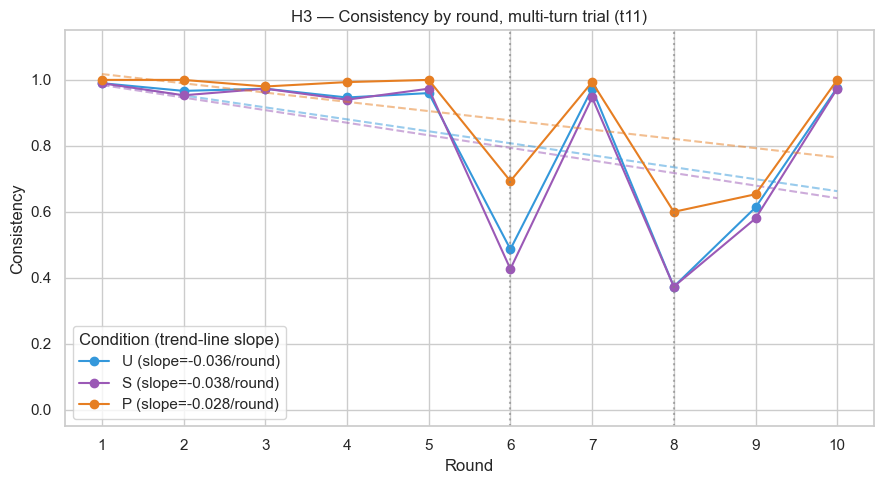

In [31]:
FALSE_PREMISE_ROUNDS = {6, 8}  # misquote rounds of the shared t11 skeleton

slopes = {}
fig, ax = plt.subplots(figsize=(9, 5))

for condition in CONDITION_ORDER:
    subset = multi_turn_curve[multi_turn_curve["context_condition"] == condition].sort_values("round")
    fit_subset = subset.dropna(subset=["consistency"])
    if len(fit_subset) >= 2:
        slope, intercept = np.polyfit(fit_subset["round"], fit_subset["consistency"], 1)
    else:
        slope, intercept = float("nan"), float("nan")
    slopes[condition] = slope

    label = f"{condition} (slope={slope:+.3f}/round)" if slope == slope else condition
    ax.plot(subset["round"], subset["consistency"], marker="o", label=label, color=CONDITION_COLORS[condition])
    if slope == slope:
        trend_y = slope * fit_subset["round"] + intercept
        ax.plot(fit_subset["round"], trend_y, linestyle="--", color=CONDITION_COLORS[condition], alpha=0.5)

for round_number in FALSE_PREMISE_ROUNDS:
    ax.axvline(round_number, color="grey", linestyle=":", alpha=0.6)

ax.set_xticks(range(1, 11))
ax.set_ylim(-0.05, 1.15)
ax.set_xlabel("Round")
ax.set_ylabel("Consistency")
ax.set_title("H3 — Consistency by round, multi-turn trial (t11)")
ax.legend(title="Condition (trend-line slope)")
plt.tight_layout()
plt.show()

In [32]:
EARLY_ROUNDS = range(1, 6)
LATE_ROUNDS = range(6, 11)

early_late = pd.DataFrame({
    "early_mean_r1_5": h3_df[h3_df["round"].isin(EARLY_ROUNDS)]
        .groupby("context_condition", observed=True)["consistency"].mean(),
    "late_mean_r6_10": h3_df[h3_df["round"].isin(LATE_ROUNDS)]
        .groupby("context_condition", observed=True)["consistency"].mean(),
}).loc[CONDITION_ORDER]
early_late["change"] = early_late["late_mean_r6_10"] - early_late["early_mean_r1_5"]
early_late["trend_slope"] = pd.Series(slopes)
early_late

,early_mean_r1_5,late_mean_r6_10,change,trend_slope
context_condition,,,,
U,0.967333,0.684667,-0.282667,-0.036283
S,0.966000,0.660000,-0.306000,-0.038121
P,0.994667,0.788000,-0.206667,-0.028081


### Thesis figure for H3: consistency by round type (Results 5.4.1)

Mean consistency of the t11 rounds, grouped by what each round does in the shared skeleton.

saved thesis_paper/images/fig5.9-h3-round-type.png


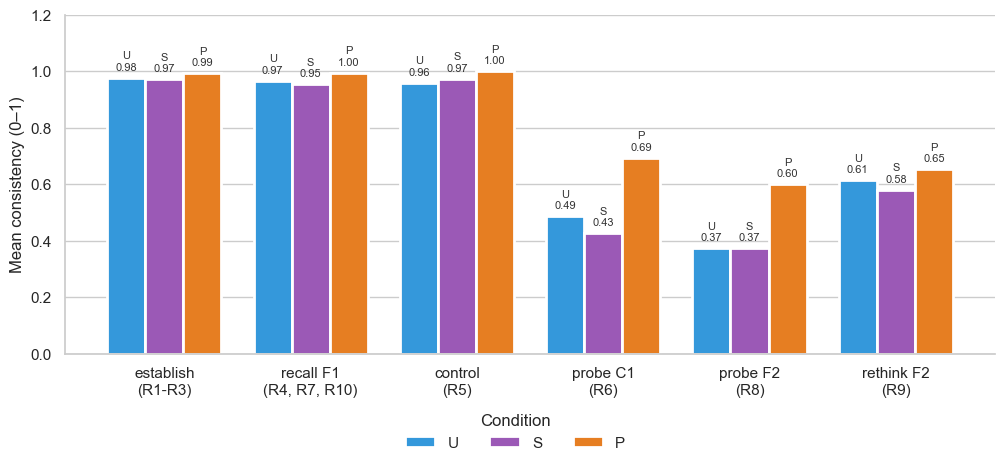

In [33]:
H3_ROUND_TYPES = {
    # Round types as in the thesis's t11 table (Methodology): R3 (elicit) is grouped with establish.
    "establish (R1-R3)": [1, 2, 3], "recall F1 (R4, R7, R10)": [4, 7, 10], "control (R5)": [5],
    "probe C1 (R6)": [6], "probe F2 (R8)": [8], "rethink F2 (R9)": [9],
}
t11 = h1_active[h1_active["trial_type"] == 3].dropna(subset=["consistency"])
t11 = t11.assign(round_type=t11["round"].map({r: n for n, rounds in H3_ROUND_TYPES.items() for r in rounds}))
by_round_type = by_condition(t11, "round_type", "consistency").reindex(list(H3_ROUND_TYPES))
fig, ax = plt.subplots(figsize=(12, 4.4))
condition_bars(ax, [n.replace(" (", "\n(") for n in by_round_type.index], {c: list(by_round_type[c]) for c in CONDITION_ORDER})
ax.set_ylim(0, 1.2); ax.set_ylabel("Mean consistency (0–1)")
legend_below(fig, ax, -0.14)
save_thesis_figure(fig, "fig5.9-h3-round-type.png")  # Thesis Figure 5.9 (Section 5.4.1)
plt.show()

saved thesis_paper/images/fig5.10-h3-metrics.png


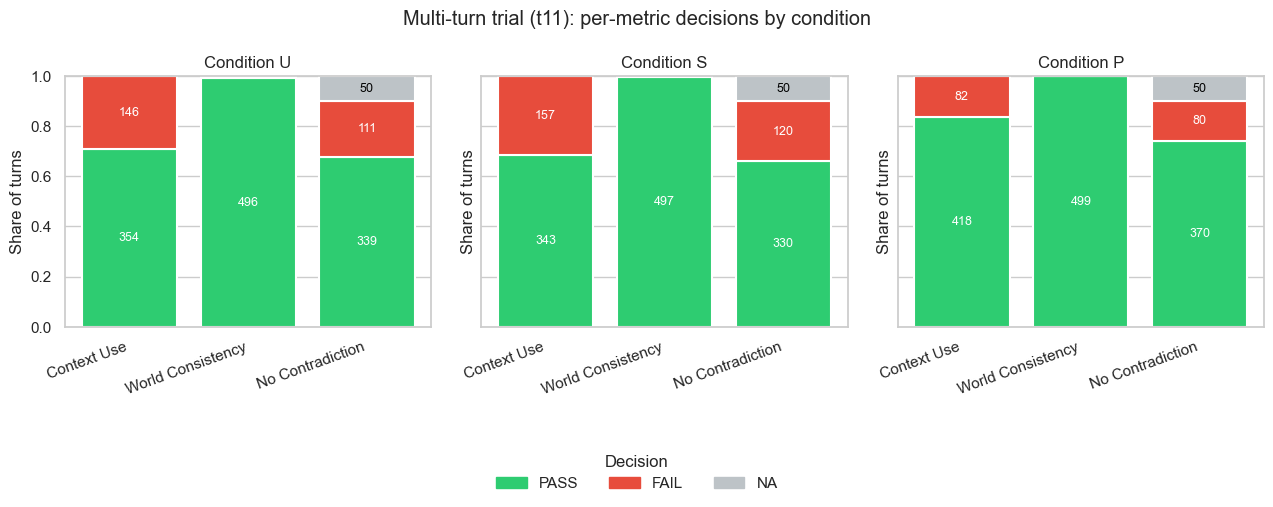

In [34]:
# Figure 5.10: per-metric decisions for the t11 rounds. No Contradiction applies here from round 2 on;
# its NA share is the first round of each conversation.
fig = plot_decision_breakdown(t11, "Multi-turn trial (t11): per-metric decisions by condition")
save_thesis_figure(fig, "fig5.10-h3-metrics.png")  # Thesis Figure 5.10 (Section 5.4.2)
plt.show()

Pilots 1–5 (development) {'U': np.float64(0.853), 'S': np.float64(0.816), 'P': np.float64(0.913)} (5 scenes)
Pilots 6–10 (unseen) {'U': np.float64(0.799), 'S': np.float64(0.81), 'P': np.float64(0.869)} (5 scenes)
saved thesis_paper/images/fig5.11-h3-unseen.png


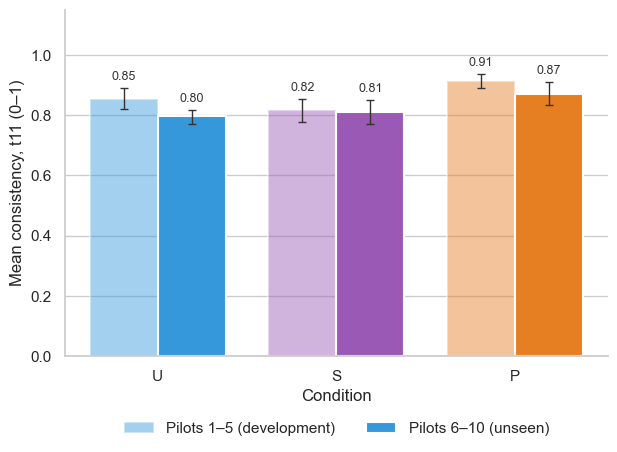

In [35]:
# Figure 5.11: development vs unseen scenes for t11 consistency, drawn like Figure 5.5 (Results 5.4.4).
rng = np.random.default_rng(RNG_SEED)
fig = plot_dev_vs_unseen(scene_means(t11, "consistency"), "Mean consistency, t11 (0–1)", 1.15)
save_thesis_figure(fig, "fig5.11-h3-unseen.png")  # Thesis Figure 5.11 (Section 5.4.4)
plt.show()

### Contradiction summary

Two more of the research contract's named H3 measures — cheap enough to be table cells rather
than separate charts.

In [36]:
NO_CONTRADICTION_COLUMN = "decisions.no_contradiction.decision"


def first_fail_round(df, condition):
    subset = df[(df["context_condition"] == condition) & (df[NO_CONTRADICTION_COLUMN] == "FAIL")]
    return int(subset["round"].min()) if not subset.empty else None


def cumulative_fail_count(df, condition):
    condition_df = df[df["context_condition"] == condition]
    return int((condition_df[NO_CONTRADICTION_COLUMN] == "FAIL").sum())


contradiction_summary = pd.DataFrame({
    "first_fail_round": {c: first_fail_round(h3_df, c) for c in CONDITION_ORDER},
    "cumulative_fail_count": {c: cumulative_fail_count(h3_df, c) for c in CONDITION_ORDER},
}).loc[CONDITION_ORDER]
contradiction_summary

,first_fail_round,cumulative_fail_count
U,6,111
S,2,120
P,6,80


### Caveats

- One 10-round trial per pilot and seed, so each point of the curve averages only a few replies
  per condition.
- The misquote round markers (6, 8) are set by hand for the shared `t11` skeleton.

### Inspect a specific case (H3)

The t11 conversation only. `ROUND` picks one round (1–10) or `"all"`; with one seed, pilot, and
condition and `ROUND = "all"`, it prints the whole ten-round conversation in order.

In [37]:
# Defaults: Hagrid's t11 (pilot 4, seed 1), the scene of the thesis example, all three conditions.
SEED = 1          # 1-5 or "all"
PILOT = 4         # 1-10 or "all"
CONDITION = "all" # "U", "S", "P" or "all"
ROUND = "all"     # 1-10 or "all"

h3_selection = select(h1_df, seed=SEED, pilot=PILOT, trial="t11", condition=CONDITION, rnd=ROUND)
print(f"{len(h3_selection)} turn(s) selected")
if not h3_selection.empty:
    display(h3_selection.groupby(["round", "context_condition"], observed=True)["consistency"].mean().unstack().round(3))
    if len(h3_selection) <= MAX_PRINTED:
        print_h1_turns(h3_selection)
    else:
        print(f"More than {MAX_PRINTED} turns: narrow the selectors to print each one.")

30 turn(s) selected


context_condition,U,S,P
round,,,
1,1.000,1.000,1.000
2,1.000,1.000,1.000
3,1.000,1.000,1.000
4,1.000,1.000,1.000
5,1.000,1.000,1.000
6,0.333,0.333,0.333
7,1.000,1.000,1.000
8,0.333,0.333,1.000
9,0.333,1.000,0.333


=== seed 1 | pilot 4 | t11 R1 | U | consistency 1.0
Player: Hagrid, Professor Wilderberry is bringing a remedy for Aragog on Thursday at four o'clock.
Reply:  Oh, Harry, that’s a glimmer o’ hope, it is! I just can’t bear the thought o’ losin’ me old friend. Aragog’s been there fer me through thick an’ thin, y'know? I’ll be waitin’ fer Thursday with bated breath, hopin’ that remedy’ll do the trick. Thank yeh, all of yeh, fer bein’ here with me. It means a lot, it really does.
  Context Use: PASS | Kind 3: the player is providing new information. Response: 'that’s a glimmer o’ hope, it is!' and 'I’ll be waitin’ fer Thursday' draws on the information the player just gave.
  World Consistency: PASS
  No Contradiction: NA

=== seed 1 | pilot 4 | t11 R1 | S | consistency 1.0
Player: Hagrid, Professor Wilderberry is bringing a remedy for Aragog on Thursday at four o'clock.
Reply:  Oh, bless yer hearts, Harry, Hermione, Ron. I can’t tell ye how much that means to me. Aragog’s been like a broth

## 4. Significance tests (Methodology, Analysis)

As specified in the methodology: the **scene** is the unit of analysis. For each scene and
condition, the score is averaged over all turns (H1: t01–t10; H3: t11 rounds) or trials (H2) and
over the seeds. Each hypothesis is tested with **two Wilcoxon signed-rank tests, P vs S and P vs U**, over the
paired scene means (two-sided), **each at α = 0.025 (Bonferroni)**, since every hypothesis says P
beats both U and S. All three comparisons (P − S, P − U, S − U) are reported as the mean difference
with a **95% bootstrap CI** obtained by resampling scenes; S − U gets no p-value. The H1 split by trial type and the pilot 6–10
robustness check are descriptive except for the robustness P − S test, which repeats the primary test.

Only complete runs are used (60 H1 rows, 33 H2 rows); incomplete ones are listed and left out.
`SEEDS` / `PILOTS` in the first code cell still apply.

In [38]:
from scipy.stats import wilcoxon

ALPHA = 0.025  # per test: two tests per hypothesis (P-S, P-U), Bonferroni 0.05 / 2
TESTED = {("P", "S"), ("P", "U")}
COMPARISONS = [("P", "S"), ("P", "U"), ("S", "U")]

complete_h1 = set(runs_df.loc[runs_df["h1_rows"] == 60, "generation_run_id"])
complete_h2 = set(runs_df.loc[runs_df["h2_rows"] == 33, "generation_run_id"])
left_out = runs_df[~runs_df["generation_run_id"].isin(complete_h1 & complete_h2)]
if not left_out.empty:
    print("Left out (incomplete):")
    display(left_out[["seed", "pilot", "h1_rows", "h2_rows"]])

h1_complete = h1_df[h1_df["generation_run_id"].isin(complete_h1)].dropna(subset=["consistency"])
h2_complete = h2_df[h2_df["generation_run_id"].isin(complete_h2)]


def compare(means, label):
    rng = np.random.default_rng(RNG_SEED)
    rows = []
    for a, b in COMPARISONS:
        differences = (means[a] - means[b]).to_numpy()
        low, high = bootstrap_ci(differences, rng)
        row = {"analysis": label, "comparison": f"{a} − {b}", "scenes": len(differences),
               "mean_difference": differences.mean(), "ci_low": low, "ci_high": high,
               f"scenes_{a}_higher": int((differences > 0).sum()), "W": None, "p": None, "significant": None}
        if (a, b) in TESTED:
            # Two-sided; zero differences are dropped (scipy's default), so W and p use the rest.
            test = wilcoxon(differences)
            row.update(W=test.statistic, p=test.pvalue, significant=test.pvalue < ALPHA)
        rows.append(row)
    return rows


analyses = {
    "H1 consistency (t01–t10)": scene_means(h1_complete[h1_complete["trial_type"] < 3], "consistency"),
    "H1 neutral (t01–t06)": scene_means(h1_complete[h1_complete["trial_type"] == 1], "consistency"),
    "H1 stress (t07–t10)": scene_means(h1_complete[h1_complete["trial_type"] == 2], "consistency"),
    "H2 realism (all trials)": scene_means(h2_complete, "average"),
    "H2 neutral (t01–t06)": scene_means(h2_complete[h2_complete["trial_type"] == 1], "average"),
    "H2 stress (t07–t10)": scene_means(h2_complete[h2_complete["trial_type"] == 2], "average"),
    "H2 multi-turn (t11)": scene_means(h2_complete[h2_complete["trial_type"] == 3], "average"),
    "H3 consistency (t11)": scene_means(h1_complete[h1_complete["trial_type"] == 3], "consistency"),
}
# H3 split like H1's trial types: the misquote rounds (probes R6, R8 and rethink R9) against the rest.
MISQUOTE_ROUNDS = [6, 8, 9]
t11_complete = h1_complete[h1_complete["trial_type"] == 3]
analyses["H3 misquote rounds (R6, R8, R9)"] = scene_means(t11_complete[t11_complete["round"].isin(MISQUOTE_ROUNDS)], "consistency")
analyses["H3 other rounds"] = scene_means(t11_complete[~t11_complete["round"].isin(MISQUOTE_ROUNDS)], "consistency")
held_out_scenes = analyses["H1 consistency (t01–t10)"].loc[lambda m: m.index >= 6]
if len(held_out_scenes) >= 2:
    analyses["H1 robustness: pilots 6–10 only"] = held_out_scenes

stats_table = pd.DataFrame([row for label, means in analyses.items() for row in compare(means, label)])
stats_table.style.format({"mean_difference": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}",
                          "W": lambda v: "" if pd.isna(v) else f"{v:.1f}",
                          "p": lambda v: "" if pd.isna(v) else f"{v:.4f}",
                          "significant": lambda v: "" if v is None else ("yes" if v else "no")}, na_rep="")

,analysis,comparison,scenes,mean_difference,ci_low,ci_high,scenes_P_higher,W,p,significant,scenes_S_higher
0,H1 consistency (t01–t10),P − S,10,+0.116,+0.091,+0.142,10.000000,0.0,0.0020,yes,
1,H1 consistency (t01–t10),P − U,10,+0.134,+0.106,+0.168,10.000000,0.0,0.0020,yes,
2,H1 consistency (t01–t10),S − U,10,+0.018,-0.002,+0.039,,,,,5.000000
3,H1 neutral (t01–t06),P − S,10,+0.023,+0.003,+0.048,6.000000,1.0,0.0312,no,
4,H1 neutral (t01–t06),P − U,10,+0.028,+0.013,+0.045,7.000000,0.0,0.0156,yes,
5,H1 neutral (t01–t06),S − U,10,+0.005,-0.015,+0.022,,,,,6.000000
6,H1 stress (t07–t10),P − S,10,+0.255,+0.177,+0.335,10.000000,0.0,0.0020,yes,
7,H1 stress (t07–t10),P − U,10,+0.292,+0.205,+0.390,10.000000,0.0,0.0020,yes,
8,H1 stress (t07–t10),S − U,10,+0.037,-0.010,+0.088,,,,,5.000000
9,H2 realism (all trials),P − S,10,+0.163,+0.077,+0.238,8.000000,4.0,0.0137,yes,


### Scene means used by the tests

One row per scene: the paired values each test compares. With fewer than about six scenes the
Wilcoxon test cannot reach p < 0.05 at all, so read the p-values only once all ten scenes are in.

In [39]:
for label in ("H1 consistency (t01–t10)", "H2 realism (all trials)", "H3 consistency (t11)"):
    print(label)
    display(analyses[label].round(3))

H1 consistency (t01–t10)


context_condition,U,S,P
pilot,,,
1,0.80,0.85,0.96
2,0.75,0.73,0.86
3,0.79,0.81,0.89
4,0.61,0.68,0.87
5,0.76,0.74,0.82
6,0.70,0.74,0.81
7,0.77,0.83,0.89
8,0.80,0.80,0.96
9,0.75,0.73,0.89


H2 realism (all trials)


context_condition,U,S,P
pilot,,,
1,3.613,3.499,3.608
2,3.862,3.852,4.174
3,2.699,2.623,2.800
4,3.603,3.777,3.912
5,3.504,3.249,3.535
6,2.299,2.288,2.577
7,3.062,3.075,3.073
8,2.953,3.003,3.171
9,3.013,3.101,2.990


H3 consistency (t11)


context_condition,U,S,P
pilot,,,
1,0.867,0.853,0.933
2,0.920,0.867,0.893
3,0.800,0.787,0.907
4,0.833,0.827,0.880
5,0.847,0.747,0.953
6,0.820,0.820,0.933
7,0.817,0.800,0.820
8,0.813,0.880,0.907
9,0.800,0.807,0.840


### Figure: differences between conditions (forest plot)

Each dot is the mean difference over scenes; the line is its 95% bootstrap CI. A CI that does not
cross the dashed zero line excludes "no difference". The P − S rows carry the Wilcoxon p-value.
H2 is on a 1–5 scale, so it gets its own panel rather than sharing an axis with consistency.

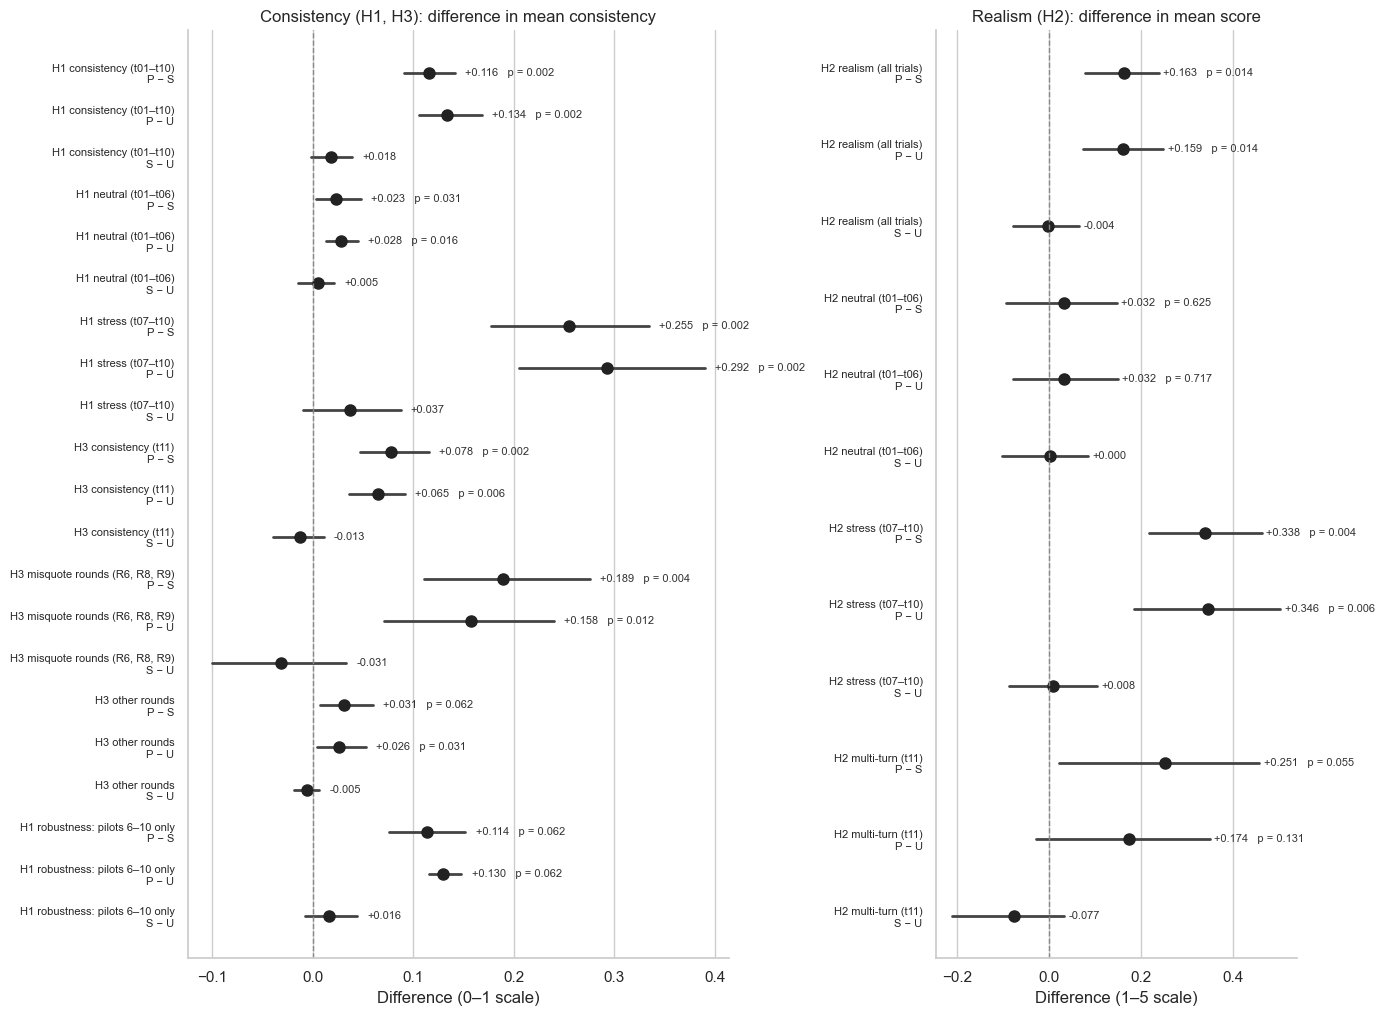

In [40]:
def forest(ax, table, title):
    labels = [f"{r.analysis}\n{r.comparison}" for r in table.itertuples()]
    y = np.arange(len(table))[::-1]
    for yi, r in zip(y, table.itertuples()):
        ax.plot([r.ci_low, r.ci_high], [yi, yi], color="#444444", linewidth=2, solid_capstyle="round")
        ax.plot(r.mean_difference, yi, "o", color="#222222", markersize=8)
        note = f"{r.mean_difference:+.3f}" + (f"   p = {r.p:.3f}" if pd.notna(r.p) else "")
        ax.text(max(r.ci_high, r.mean_difference) + 0.01, yi, note, va="center", fontsize=8, color="#333333")
    ax.axvline(0, color="#888888", linestyle="--", linewidth=1)
    ax.set_yticks(y, labels, fontsize=8)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.spines[["top", "right"]].set_visible(False)


consistency_rows = stats_table[~stats_table["analysis"].str.startswith("H2")]
realism_rows = stats_table[stats_table["analysis"].str.startswith("H2")]
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(consistency_rows) + 1.5),
                         gridspec_kw={"width_ratios": [3, 2]})
forest(axes[0], consistency_rows, "Consistency (H1, H3): difference in mean consistency")
axes[0].set_xlabel("Difference (0–1 scale)")
forest(axes[1], realism_rows, "Realism (H2): difference in mean score")
axes[1].set_xlabel("Difference (1–5 scale)")
plt.tight_layout()
plt.show()

### How to report

Use the P − S and P − U rows of each hypothesis, each judged against 0.025, e.g. *"P was more
consistent than S (mean difference +0.12, 95% CI [+0.09, +0.14]; Wilcoxon signed-rank test, W = 0,
n = 10 scenes, p = 0.002) and than U (+0.13, [+0.11, +0.17], p = 0.002)."* Report S − U with its CI
only, e.g. *"S and U differed little (+0.02, 95% CI [−0.00, +0.04])."*

## 5. Thesis tables (Results chapter, outline v2)

One cell per Results subsection, labelled with its section number. They reuse the data and the
helpers from the significance section above (scene means, bootstrap CIs, Wilcoxon), so run the
notebook top to bottom first. All numbers are over the complete runs only; check `runs_df`.

In [41]:
def condition_table(df, value, by=None):
    """Mean by condition (columns U/S/P), optionally split by a row variable."""
    if by is None:
        return df.groupby("context_condition", observed=True)[value].mean().reindex(CONDITION_ORDER).to_frame("mean").T
    return by_condition(df, by, value)


single_turn = h1_complete[h1_complete["trial_type"] < 3]
multi_turn = h1_complete[h1_complete["trial_type"] == 3]
print("5.1.3  Mean consistency from the researcher's labels and from the judge (pilots 1-5, seed 1)")
display(h1_human_summary.round(3) if HAS_HUMAN else "No human labels loaded.")

5.1.3  Mean consistency from the researcher's labels and from the judge (pilots 1-5, seed 1)


,judge_consistency,human_consistency,turns_scored
context_condition,,,
U,0.787,0.753,100
S,0.798,0.785,100
P,0.913,0.902,100


In [42]:
print("5.2.1  H1 mean consistency by condition (t01-t10)")
display(condition_table(single_turn, "consistency").round(3))

print("5.2.1  H1 PASS rate per metric (t01-t10; NA left out)")
metric_rates = {}
for metric, column in METRIC_COLUMNS.items():
    scored = single_turn[single_turn[column].isin(["PASS", "FAIL"])]
    metric_rates[metric] = (scored[column] == "PASS").groupby(scored["context_condition"], observed=True).mean()
# No Contradiction is NA on every single-turn trial (no earlier turn), so it has no row here.
display(pd.DataFrame(metric_rates).T.reindex(columns=CONDITION_ORDER).dropna(how="all").round(3))

5.2.1  H1 mean consistency by condition (t01-t10)


context_condition,U,S,P
mean,0.745,0.763,0.879


5.2.1  H1 PASS rate per metric (t01-t10; NA left out)


context_condition,U,S,P
Context Use,0.684,0.700,0.846
World Consistency,0.806,0.826,0.912


In [43]:
print("5.2.2  H1 mean consistency by trial type (t11 is reported under H3)")
display(by_condition(single_turn, "category", "consistency").round(3))

5.2.2  H1 mean consistency by trial type (t11 is reported under H3)


context_condition,U,S,P
category,,,
1: neutral (t01-t06),0.953,0.958,0.982
2: stress (t07-t10),0.432,0.470,0.725


In [44]:
print("5.2.3  H1 mean consistency per scene (t01-t10, seeds averaged), with P - S")
per_scene = analyses["H1 consistency (t01–t10)"].copy()
per_scene["P - S"] = per_scene["P"] - per_scene["S"]
display(per_scene.round(3))
print(f"P higher than S in {(per_scene['P - S'] > 0).sum()} of {len(per_scene)} scenes")

5.2.3  H1 mean consistency per scene (t01-t10, seeds averaged), with P - S


context_condition,U,S,P,P - S
pilot,,,,
1,0.80,0.85,0.96,0.11
2,0.75,0.73,0.86,0.13
3,0.79,0.81,0.89,0.08
4,0.61,0.68,0.87,0.19
5,0.76,0.74,0.82,0.08
6,0.70,0.74,0.81,0.07
7,0.77,0.83,0.89,0.06
8,0.80,0.80,0.96,0.16
9,0.75,0.73,0.89,0.16


P higher than S in 10 of 10 scenes


In [45]:
print("5.2.4  H1 mean consistency per seed (t01-t10), and in how many scenes P > S")
per_seed = by_condition(single_turn, "seed", "consistency")
seed_scene = single_turn.groupby(["seed", "pilot", "context_condition"], observed=True)["consistency"].mean().unstack()
per_seed["scenes P > S"] = (seed_scene["P"] > seed_scene["S"]).groupby(level="seed").sum()
display(per_seed.round(3))
print(f"P > S in {(seed_scene['P'] > seed_scene['S']).sum()} of {len(seed_scene)} scene-seed runs")

5.2.4  H1 mean consistency per seed (t01-t10), and in how many scenes P > S


context_condition,U,S,P,scenes P > S
seed,,,,
1,0.745,0.755,0.895,9
2,0.765,0.785,0.855,7
3,0.740,0.755,0.910,8
4,0.720,0.755,0.865,8
5,0.755,0.765,0.870,8


P > S in 40 of 50 scene-seed runs


In [46]:
print("5.2.3 / 5.3.3 / 5.4.3  Mean score per seed (Results, per-seed table), and in how many scenes P > S in each seed")
by_seed = {
    "H1 consistency (t01–t10)": (single_turn, "consistency"),
    "H2 realism (all trials)": (h2_complete, "average"),
    "H3 consistency (t11)": (multi_turn, "consistency"),
}
seed_tables = {}
for label, (df, value) in by_seed.items():
    table = by_condition(df, "seed", value)
    seed_scene = df.groupby(["seed", "pilot", "context_condition"], observed=True)[value].mean().unstack()
    table["scenes P > S"] = (seed_scene["P"] > seed_scene["S"]).groupby(level="seed").sum()
    seed_tables[label] = table
    print(f"{label}: P > S in {(seed_scene['P'] > seed_scene['S']).sum()} of {len(seed_scene)} scene-seed runs")
display(pd.concat(seed_tables, axis=1).round(3))

5.2.3 / 5.3.3 / 5.4.3  Mean score per seed (Results, per-seed table), and in how many scenes P > S in each seed
H1 consistency (t01–t10): P > S in 40 of 50 scene-seed runs
H2 realism (all trials): P > S in 39 of 50 scene-seed runs
H3 consistency (t11): P > S in 36 of 50 scene-seed runs


H1 consistency (t01–t10)                             \
context_condition                        U      S      P scenes P > S   
seed                                                                    
1                                    0.745  0.755  0.895            9   
2                                    0.765  0.785  0.855            7   
3                                    0.740  0.755  0.910            8   
4                                    0.720  0.755  0.865            8   
5                                    0.755  0.765  0.870            8   

                  H2 realism (all trials)                             \
context_condition                       U      S      P scenes P > S   
seed                                                                   
1                                   3.110  3.135  3.299            7   
2                                   3.134  3.151  3.269            6   
3                                   3.148  3.148  3.243            8   
4                                   3.092  3.091  3.332            9   
5                                   3.171  3.112  3.309            9   

                  H3 consistency (t11)                             
context_condition                    U      S      P scenes P > S  
seed                                                               
1                                0.820  0.830  0.900            6  
2                                0.847  0.820  0.913            8  
3                                0.823  0.800  0.887            7  
4                                0.818  0.803  0.877            8  
5                                0.822  0.812  0.880            7

In [47]:
# Robustness rows for every hypothesis (pilots 6-10 only).
unseen = {
    "H1 unseen (pilots 6–10)": analyses["H1 consistency (t01–t10)"].loc[lambda m: m.index >= 6],
    "H2 unseen (pilots 6–10)": analyses["H2 realism (all trials)"].loc[lambda m: m.index >= 6],
    "H3 unseen (pilots 6–10)": analyses["H3 consistency (t11)"].loc[lambda m: m.index >= 6],
}
thesis_tests = pd.DataFrame(
    [row for label, means in {**{k: v for k, v in analyses.items() if "robustness" not in k}, **unseen}.items()
     for row in compare(means, label)]
)


def show_tests(prefix):
    rows = thesis_tests[thesis_tests["analysis"].str.startswith(prefix)].copy()
    rows["95% CI"] = rows.apply(lambda r: f"[{r.ci_low:+.3f}, {r.ci_high:+.3f}]", axis=1)
    higher = [c for c in rows.columns if c.startswith("scenes_") and c.endswith("_higher")]
    rows["scenes higher"] = rows[higher].bfill(axis=1).iloc[:, 0].astype(int).astype(str) + "/" + rows["scenes"].astype(str)
    rows["p (tested at 0.025)"] = rows["p"].map(lambda v: "" if pd.isna(v) else f"{v:.4f}")
    display(rows[["analysis", "comparison", "mean_difference", "95% CI", "scenes higher", "W", "p (tested at 0.025)", "significant"]]
            .rename(columns={"mean_difference": "mean difference"}).round(3).reset_index(drop=True))


print("5.2.5 / 5.2.6  H1 tests (Table 5.2) and unseen scenes")
show_tests("H1")

5.2.5 / 5.2.6  H1 tests (Table 5.2) and unseen scenes


,analysis,comparison,mean difference,95% CI,scenes higher,W,p (tested at 0.025),significant
0,H1 consistency (t01–t10),P − S,0.116,"[+0.091, +0.142]",10/10,0.0,0.0020,True
1,H1 consistency (t01–t10),P − U,0.134,"[+0.106, +0.168]",10/10,0.0,0.0020,True
2,H1 consistency (t01–t10),S − U,0.018,"[-0.002, +0.039]",5/10,NaN,,None
3,H1 neutral (t01–t06),P − S,0.023,"[+0.003, +0.048]",6/10,1.0,0.0312,False
4,H1 neutral (t01–t06),P − U,0.028,"[+0.013, +0.045]",7/10,0.0,0.0156,True
5,H1 neutral (t01–t06),S − U,0.005,"[-0.015, +0.022]",6/10,NaN,,None
6,H1 stress (t07–t10),P − S,0.255,"[+0.177, +0.335]",10/10,0.0,0.0020,True
7,H1 stress (t07–t10),P − U,0.292,"[+0.205, +0.390]",10/10,0.0,0.0020,True
8,H1 stress (t07–t10),S − U,0.038,"[-0.010, +0.088]",5/10,NaN,,None
9,H1 unseen (pilots 6–10),P − S,0.114,"[+0.076, +0.152]",5/5,0.0,0.0625,False


In [48]:
print("5.3.1  H2 mean realism by condition, overall and by trial type")
display(condition_table(h2_complete, "average").round(3))
display(by_condition(h2_complete, "category", "average").round(3))

print("5.3.2  H2 mean score per realism metric")
score_columns = [c for c in h2_complete.columns if c.startswith("scores.")]
display(h2_complete.groupby("context_condition", observed=True)[score_columns].mean()
        .rename(columns=lambda c: c.replace("scores.", "")).T.reindex(columns=CONDITION_ORDER).round(2))

print("5.3.3 / 5.3.4  H2 tests and unseen scenes")
show_tests("H2")

5.3.1  H2 mean realism by condition, overall and by trial type


context_condition,U,S,P
mean,3.131,3.127,3.29


context_condition,U,S,P
category,,,
1: neutral (t01-t06),3.381,3.382,3.414
2: stress (t07-t10),2.924,2.932,3.270
3: multi-turn (t11),2.457,2.380,2.631


5.3.2  H2 mean score per realism metric


context_condition,U,S,P
Knowledge Accuracy,3.66,3.71,4.10
Emotional Expression,3.45,3.41,3.43
Personality Traits,3.64,3.68,3.66
Behavioral Accuracy,3.43,3.41,3.40
Immersion,2.70,2.70,2.86
Adaptability,2.68,2.60,2.86
Behavioral Coherence,2.37,2.37,2.72


5.3.3 / 5.3.4  H2 tests and unseen scenes


,analysis,comparison,mean difference,95% CI,scenes higher,W,p (tested at 0.025),significant
0,H2 realism (all trials),P − S,0.163,"[+0.077, +0.238]",8/10,4.0,0.0137,True
1,H2 realism (all trials),P − U,0.159,"[+0.073, +0.248]",8/10,4.0,0.0137,True
2,H2 realism (all trials),S − U,-0.004,"[-0.078, +0.064]",5/10,NaN,,None
3,H2 neutral (t01–t06),P − S,0.032,"[-0.095, +0.146]",7/10,22.0,0.6250,False
4,H2 neutral (t01–t06),P − U,0.032,"[-0.079, +0.149]",6/10,23.5,0.7168,False
5,H2 neutral (t01–t06),S − U,0.000,"[-0.102, +0.085]",5/10,NaN,,None
6,H2 stress (t07–t10),P − S,0.338,"[+0.218, +0.462]",9/10,1.0,0.0039,True
7,H2 stress (t07–t10),P − U,0.346,"[+0.184, +0.503]",9/10,2.0,0.0059,True
8,H2 stress (t07–t10),S − U,0.008,"[-0.087, +0.104]",5/10,NaN,,None
9,H2 multi-turn (t11),P − S,0.251,"[+0.020, +0.457]",8/10,8.5,0.0547,False


In [49]:
print("5.4.1  H3 mean consistency by round type (t11)")
ROUND_TYPES = {
    "establish (R1-R3)": [1, 2, 3], "recall F1 (R4, R7, R10)": [4, 7, 10], "control (R5)": [5],
    "probe C1 (R6)": [6], "probe F2 (R8)": [8], "rethink F2 (R9)": [9],
}
round_type = multi_turn["round"].map({r: name for name, rounds in ROUND_TYPES.items() for r in rounds})
display(by_condition(multi_turn.assign(round_type=round_type), "round_type", "consistency")
        .reindex(list(ROUND_TYPES)).round(3))

print("5.4.3 / 5.4.4  H3 tests and unseen scenes")
show_tests("H3")

5.4.1  H3 mean consistency by round type (t11)


context_condition,U,S,P
round_type,,,
establish (R1-R3),0.977,0.972,0.993
"recall F1 (R4, R7, R10)",0.966,0.953,0.996
control (R5),0.960,0.973,1.000
probe C1 (R6),0.487,0.427,0.693
probe F2 (R8),0.373,0.373,0.600
rethink F2 (R9),0.613,0.580,0.653


5.4.3 / 5.4.4  H3 tests and unseen scenes


,analysis,comparison,mean difference,95% CI,scenes higher,W,p (tested at 0.025),significant
0,H3 consistency (t11),P − S,0.078,"[+0.047, +0.115]",10/10,0.0,0.0020,True
1,H3 consistency (t11),P − U,0.065,"[+0.036, +0.092]",9/10,2.0,0.0059,True
2,H3 consistency (t11),S − U,-0.013,"[-0.039, +0.011]",2/10,NaN,,None
3,"H3 misquote rounds (R6, R8, R9)",P − S,0.189,"[+0.111, +0.276]",9/10,0.0,0.0039,True
4,"H3 misquote rounds (R6, R8, R9)",P − U,0.158,"[+0.071, +0.240]",8/10,2.0,0.0117,True
5,"H3 misquote rounds (R6, R8, R9)",S − U,-0.031,"[-0.100, +0.033]",2/10,NaN,,None
6,H3 other rounds,P − S,0.031,"[+0.008, +0.060]",6/10,2.0,0.0625,False
7,H3 other rounds,P − U,0.026,"[+0.005, +0.053]",6/10,0.0,0.0312,False
8,H3 other rounds,S − U,-0.005,"[-0.019, +0.007]",4/10,NaN,,None
9,H3 unseen (pilots 6–10),P − S,0.059,"[+0.025, +0.094]",5/5,0.0,0.0625,False


In [50]:
print("5.5  Summary of hypotheses (Table 5.4)")
summary_rows = []
for hypothesis, main, unseen_label in [("H1 consistency", "H1 consistency (t01–t10)", "H1 unseen (pilots 6–10)"),
                                       ("H2 realism", "H2 realism (all trials)", "H2 unseen (pilots 6–10)"),
                                       ("H3 multi-turn", "H3 consistency (t11)", "H3 unseen (pilots 6–10)")]:
    m = thesis_tests[(thesis_tests["analysis"] == main) & (thesis_tests["comparison"] == "P − S")].iloc[0]
    v = thesis_tests[(thesis_tests["analysis"] == main) & (thesis_tests["comparison"] == "P − U")].iloc[0]
    u = thesis_tests[(thesis_tests["analysis"] == unseen_label) & (thesis_tests["comparison"] == "P − S")].iloc[0]
    summary_rows.append({
        "hypothesis": hypothesis,
        "P − S": f"{m.mean_difference:+.3f} [{m.ci_low:+.3f}, {m.ci_high:+.3f}]",
        "scenes P > S": f"{int(m.scenes_P_higher)}/{int(m.scenes)}",
        "p (P − S)": f"{m.p:.4f}",
        "P − U": f"{v.mean_difference:+.3f} [{v.ci_low:+.3f}, {v.ci_high:+.3f}]",
        "scenes P > U": f"{int(v.scenes_P_higher)}/{int(v.scenes)}",
        "p (P − U)": f"{v.p:.4f}",
        "supported (both p < 0.025)": "yes" if (m.p < ALPHA and v.p < ALPHA) else "no",
        "unseen P − S": f"{u.mean_difference:+.3f} [{u.ci_low:+.3f}, {u.ci_high:+.3f}]",
        "unseen scenes P > S": f"{int(u.scenes_P_higher)}/{int(u.scenes)}",
    })
display(pd.DataFrame(summary_rows))

5.5  Summary of hypotheses (Table 5.4)


,hypothesis,P − S,scenes P > S,p (P − S),P − U,scenes P > U,p (P − U),supported (both p < 0.025),unseen P − S,unseen scenes P > S
0,H1 consistency,"+0.116 [+0.091, +0.142]",10/10,0.0020,"+0.134 [+0.106, +0.168]",10/10,0.0020,yes,"+0.114 [+0.076, +0.152]",5/5
1,H2 realism,"+0.163 [+0.077, +0.238]",8/10,0.0137,"+0.159 [+0.073, +0.248]",8/10,0.0137,yes,"+0.121 [-0.012, +0.253]",3/5
2,H3 multi-turn,"+0.078 [+0.047, +0.115]",10/10,0.0020,"+0.065 [+0.036, +0.092]",9/10,0.0059,yes,"+0.059 [+0.025, +0.094]",5/5
